# NYC 311 Complaints and Weather

*Tristan Albano, Diya Bhageria, Addison Heffernan, and Samuel Rabinor · INFO 2950, Fall 2026*

## Introduction

New York City's **311** system is how residents ask the city for non-emergency help: a building with no heat, a flooded street, a fallen tree,
a loud party next door. It receives millions of requests a year (about 22 million from January 2020 to August 2026 in our data), and city agencies
use those requests to decide where to send inspectors, plumbers, and tree crews.

Many of these problems are tied to the weather. NYC landlords must provide heat from October 1 through May 31 (NYC Department of Housing Preservation and Development, n.d.),
so a cold snap can bring thousands of heat complaints in a single day. Heavy rain overloads sewers, strong wind knocks down trees, and snow buries sidewalks.
Warm evenings bring people outside and, with them, noise and fireworks complaints. If the city knows how each type of complaint reacts to the weather,
it can plan staff before a storm or a cold snap instead of after. It also matters *who* does the reporting: 311 counts depend on which residents call,
which can lead to unequal service across neighborhoods (Minkoff, 2016; Kontokosta & Hong, 2021). We come back to this in the Limitations.

**Research questions**

1. **How is daily weather (temperature, precipitation, snowfall, and thunder) associated with the total number of 311 requests filed in NYC each day?**
2. **Which complaint types rise or fall on particular weather days (for example freezing, heavy-rain, windy, snowy, or hot days), and do these patterns hold after accounting for the calendar?**

In Phase 2 our second question was about broad complaint *groups* (Heat/Hot Water, Flooding/Sewer/Water, Trees, and so on). Our exploration showed that types inside one group can
behave differently, so this report studies **8 specific complaint types** chosen to react to the weather or the calendar in different ways (section 3).
We also used the second weather station (JFK) as a robustness check, as our Phase 2 reviewers suggested.

**Summary of findings**

* **Total 311 volume is only weakly related to the weather.** Contrary to our first hypothesis, warmer days have slightly *more* total reports (+22.8 per °F), and the real pattern is U-shaped,
  with the most reports on the coldest and warmest days. Thunder days have about 4.6% more reports, which passes our preregistered test, but the difference disappears
  once we account for temperature and the calendar: thunderstorms happen on summer days, which are already busy.
* **Specific complaint types react strongly to the weather they are physically tied to**, even after holding the calendar fixed: heat complaints double on freezing days,
  sewer complaints are about 4.5× higher on heavy-rain days, damaged-tree complaints about 6× higher on windy days, and snow/ice complaints about 6.5× higher on freezing days.
  Street noise falls by about half in bad weather. These effects push in opposite directions, so they largely cancel out in the citywide total.
* **A machine-learning model (XGBoost) predicts the seasonal types well** on a year it never saw (R² = 0.92 for heat, 0.91 for street noise), but it badly underestimates the
  biggest storms, which produce a large share of sewer, tree, and snow complaints.

**Notebook roadmap.** After the data description and preregistration below, sections 1–3 load the data and choose the 8 complaint types, sections 4–8 analyze them
(counts, temperature, rate ratios, an XGBoost model, and feature importance), section 9 summarizes the analysis, section 10 evaluates statistical significance and tests our
preregistered hypotheses, sections 11–12 give our conclusions and limitations, followed by our questions for reviewers and the bibliography (section 13).

## Data description and cleaning

**Data cleaning notebooks** are in our GitHub repository (https://github.com/Tavnik-7-8-22/INFO2950-Project). Running them from top to bottom on the raw files recreates the two cleaned data sets used here:
* **`ComplaintsWeather.csv`**, created by `HandwrittenExploration.ipynb` (https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/HandwrittenExploration.ipynb):
  the cleaned 311 requests, one row per request (about 22 million rows, ~7 GB), with that day's Central Park and JFK weather and calendar columns attached.
  Sections 2–9 use it. Because it is too big to load at once, section 2 reads it in chunks and saves two small daily summaries
  (`daily_complaint_type_counts.csv` and `daily_weather.csv`) that the rest of the notebook uses.
* **`data/daily_complaints_weather.csv`**, created by `nyc_311_weather_analysis.ipynb` (https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/nyc_311_weather_analysis.ipynb): daily request counts per complaint group, with the weather from both stations. Section 10 uses its daily totals to test our preregistered hypotheses.

This notebook does no further cleaning apart from choosing the study period and the 8 complaint types (section 3).

### Data sources

**311 service requests**
- **Source:** NYC Open Data, *311 Service Requests from 2020 to Present* (NYC Office of Technology and Innovation).
- **How:** exported as a CSV from the NYC Open Data website (the dataset's Export option). No code was used to collect it.
- **Query:** requests created from Jan 1, 2020 through Aug 31, 2026. The created and closed dates were truncated to the day in the export, so every time is 12:00 AM.
- **Columns kept:** Unique Key, created date, closed date, Agency, Problem (formerly Complaint Type), Problem Detail (formerly Descriptor), Additional Details, Location Type, Borough.
- **Downloaded:** September 8, 2026: 22,335,555 rows (3.2 GB), stored in the repository zipped (`311ServiceRequests.csv.zip`, 250 MB) with Git LFS.

**Weather**
- **Source:** NOAA National Centers for Environmental Information, Climate Data Online, *Daily Summaries* (GHCN-Daily; Menne et al., 2012).
- **Stations:** NY City Central Park (`USW00094728`) and JFK International Airport (`USW00094789`).
- **Dates:** Jan 1, 2020 – Sep 1, 2026, one row per day per station. Downloaded September 8, 2026, with data quality flags.
- **Why two stations:** Central Park is the standard reference station for NYC weather and is our main station. JFK fills gaps in Central Park's wind data and is a second,
  coastal measurement of the same days that we use as a robustness check.

### Data cleaning steps (summary)

- **Weather:** dropped empty and unneeded columns; filled 71 days of missing Central Park wind (and 6 JFK gusts) from the other station with a straight-line fit, and flagged them;
  converted units to °F, inches, and mph; calculated average temperature as (high + low) / 2; kept "trace" rain and snow as 0/1 columns; renamed weather-type flags
  (e.g. `WT03` → `WT_THUNDER`); removed humidity and pressure, which stop after 2024; and added calendar features (year, month, day of week, weekend, season, federal holidays).
- **311:** parsed dates; merged complaint types that differ only in spelling or capitalization (17 types) or were renamed over time (e.g. `Snow` / `Snow Removal` → `Snow or Ice`,
  and the Sept 21, 2021 sanitation relabel); moved seven COVID-only types (88,809 requests) to a separate table; assigned each type to a complaint group;
  and standardized borough, agency, and location labels.
- **Combining:** counted requests per day and complaint group (including days with zero requests), added a daily total ("All complaints"), and joined the calendar and both
  stations' weather by date. `nyc_311_weather_analysis.ipynb` saves the daily result as `data/daily_complaints_weather.csv`, and `HandwrittenExploration.ipynb` saves the request-level result as `ComplaintsWeather.csv`.
- **In this notebook (section 3):** we use daily counts of 8 individual complaint types and end the study on **July 29, 2026**, the last day sewer complaints appear in our download.

### Datasheet (following Gebru et al., 2021)

**Why was this data set created?** To study how daily weather in New York City relates to the number and type of 311 service requests. For example: do heat complaints rise on cold days,
do sewer complaints rise after heavy rain, and do noise complaints rise on warm days? **Who created it?** Tristan Albano, Diya Bhageria, Addison Heffernan, and Samuel Rabinor,
using data from NOAA and NYC Open Data.

**What are the observations (rows)?** In `data/daily_complaints_weather.csv`, each row is **one day and one complaint group**: 2,435 days (Jan 1, 2020 – Aug 31, 2026) × 10 groups
= **24,350 rows**. Nine rows per day are complaint groups, and the tenth ("All complaints") is that day's total, which we use for our preregistered hypotheses (section 10).
For the complaint-type analysis (sections 3–9), we use one row per day with the number of complaints of each of our 8 types and Central Park's weather for that day
(2,402 days, Jan 1, 2020 – Jul 29, 2026).

| Complaint group | Total requests, 2020 – Aug 2026 |
|---|---|
| Noise | 5,088,206 |
| Housing Conditions | 2,916,812 |
| Heat/Hot Water | 1,679,642 |
| Street Condition | 1,415,274 |
| Sanitation | 1,150,746 |
| Flooding/Sewer/Water | 651,612 |
| Trees | 546,766 |
| Snow/Ice | 95,418 |
| Other (all remaining types, e.g. illegal parking, blocked driveway) | 8,702,270 |
| **All complaints** | **22,246,746** |

**What are the attributes (columns)?**

| Column(s) | Meaning |
|---|---|
| `DATE` | The day the requests were created |
| `COMPLAINT_GROUP` | One of the 9 groups above, or "All complaints" |
| `REQUESTS` | Number of 311 requests created that day in that group (0 if none) |
| `YEAR`, `MONTH`, `MONTH_NAME`, `DAY_OF_WEEK` (0 = Monday), `DAY_NAME` | Calendar parts of the date |
| `IS_WEEKEND`, `IS_HOLIDAY` | 1 if Saturday/Sunday; 1 if a federal holiday (the observed day off) |
| `SEASON` | Meteorological season: Winter (Dec–Feb), Spring (Mar–May), Summer (Jun–Aug), Fall (Sep–Nov) |
| `CP_TMAX`, `CP_TMIN`, `CP_TAVG` | Central Park high, low, and average temperature (°F) |
| `CP_PRCP`, `CP_SNOW`, `CP_SNWD` | Central Park precipitation, snowfall, and snow depth (inches) |
| `CP_PRCP_TRACE`, `CP_SNOW_TRACE` | 1 if there was a trace amount (too small to measure, recorded as 0) |
| `CP_AWND`, `CP_WSF5` | Central Park average wind speed and fastest 5-second gust (mph) |
| `CP_WIND_FILLED_FROM_JFK` | 1 if Central Park's wind values that day were estimated from JFK (71 days) |
| `CP_WT_THUNDER`, `JFK_WT_THUNDER` | 1 if thunder was recorded at that station that day; 0 otherwise |
| `JFK_...` | The same weather columns for JFK Airport; `JFK_WIND_FILLED_FROM_CP` = 1 on the 6 days JFK's gust was estimated from Central Park |

**Is anything missing? Is it a sample?** No values are missing: days with no requests are recorded as 0, and the 77 days with estimated wind are flagged. The counts include every request
in the export in the date range (except the COVID-only types), but they describe *reported* requests, not all problems that happened. The weather comes from two stations, not the whole city.

**Does it contain personal or sensitive information? Does it identify subpopulations?** No. It only contains daily counts: no names, addresses, locations, or request IDs,
and no demographic information.

**What processes might have influenced what was observed and recorded?**
- **311 only records what people report.** Whether a problem becomes a request depends on whether someone notices it, knows about 311, has phone or internet access, speaks a supported
  language, and expects the city to respond. These vary across neighborhoods, so the counts measure *reporting*, not how often problems actually occur (Minkoff, 2016; Kontokosta & Hong, 2021).
- **One problem can create many requests, or none.** Many neighbors may report the same flooded street, while another problem goes unreported.
- **Categories changed over time.** 311 renamed many types (most on Sept 21, 2021), temporarily relabeled housing complaints in 2023, relabeled water and sewer complaints in July 2026,
  and added pandemic-only categories in 2020–2023. We merged or removed these, but other changes may remain.
- **Outside events change volume.** COVID-19 changed behavior in 2020–2021, and total volume rises over the period (about 2.9 million requests in 2020 vs. 3.7 million in 2025).
- **Only the day is known**, and **each weather station measures one spot**: local thunderstorms can hit one part of the city and miss Central Park.

**Were people aware of the data collection, and what did they expect it to be used for?** People who contact 311 know they are submitting information to the city and expect it to be used
to address their request. NYC publishes 311 records on NYC Open Data, but people may not expect them to be used for research like ours. Our data only contain daily counts,
so no individual can be identified. The weather data does not involve people.

**Is the data trustworthy?** Both sources are official government data sets. NOAA's GHCN-Daily data go through automated quality checks (Menne et al., 2012), and we checked our unit
conversions against known events (Hurricane Ida, the Feb 1, 2021 snowstorm, the hottest day). The 311 data are a complete record of requests as of our download date,
but NYC Open Data keeps updating its records, so a later download (especially for 2026) may give slightly different counts.

**Uses.** The data are meant for studying how daily weather relates to the daily number of 311 requests. They should **not** be used to measure how often problems actually happen,
to compare boroughs or neighborhoods, or to study time of day. Because groups that report less are undercounted, using these data to decide where to send city resources could be unfair.

### Where to find the data
- 311 service requests (zipped, 250 MB): https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/311ServiceRequests.csv.zip
- Central Park weather: https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/CentralPark.csv
- JFK weather: https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/JFK.csv
- Cleaned data set: https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/data/daily_complaints_weather.csv
- `ComplaintsWeather.csv` (cleaned requests, one row per request, ~7 GB, too big for GitHub): https://drive.google.com/file/d/1XRy05UxC0S7Dym1Spe5oeCB1QLFLW1AK/view?usp=sharing
- Original sources: NYC Open Data, https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9/about_data;
  NOAA Climate Data Online, https://www.ncei.noaa.gov/cdo-web/

## Preregistration statements

These are the two hypotheses we preregistered in Phase 2, unchanged. Both are tested in **section 10**.

### Preregistration Statement 1

**Hypothesis 1:** Colder temperatures are associated with more 311 reports.

**Analysis:** For data where each row represents a single day, we will run a linear regression with average daily temperature (in °F, using Central Park as the primary station)
as the predictor and the **total number of 311 reports** filed that day as the outcome. Because we expect reports to rise as temperatures fall, we will test whether **β_temperature < 0**.

**Definitions:** *Average daily temperature* is (daily high + daily low) / 2 at Central Park, in °F. *Total 311 reports* is the number of requests created that day in the `All complaints` series.

**Why we expect this:** NYC requires landlords to provide heat from October 1 through May 31: during the day when the outside temperature is below 55°F, and overnight regardless of the
outside temperature (NYC Department of Housing Preservation and Development, n.d.). Heat/Hot Water is one of the largest complaint categories in our data (1,679,642 requests,
about 7.5% of all requests) and is the most common complaint type in winter.

### Preregistration Statement 2

**Hypothesis 2:** Thunder is associated with more 311 reports.

**Analysis:** For data where each row represents a single day, we will run a linear regression with a thunder indicator from Central Park (1 = thunder recorded, 0 = no thunder)
as the predictor and the **total number of 311 reports** filed that day as the outcome. Days without thunder will be the reference group, so we will test whether **β_thunder > 0**.

**Definitions:** *Thunder* is NOAA's weather-type flag for thunder (`WT03`) at Central Park on that day, stored in our data as `CP_WT_THUNDER`. *Total 311 reports* is defined as in Statement 1.

**Why we expect this:** Thunderstorms bring heavy rain and strong wind in short bursts, which can flood streets, overload sewers, and knock down trees, and residents report these
problems to 311. Our data include the Flooding/Sewer/Water (651,612 requests) and Trees (546,766 requests) complaint groups.

*In both hypotheses, "total" refers to the cleaned `All complaints` daily series, which excludes the COVID-only complaint types. We report both preregistered analyses regardless of
statistical significance. Following our Phase 2 reviewers' questions, we also run calendar controls, a nonlinear temperature term, the JFK station, and next-day thunder as
clearly labeled extensions, not replacements for these primary models (section 10).*

## 1. Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
# Colors used in every chart
BLUE = "#2a78d6"
LIGHT_BLUE = "#86b6ef"
DARK_BLUE = "#1c5cab"
ORANGE = "#eb6834"
RED = "#e34948"
INK = "#0b0b0b"
MUTED_INK = "#52514e"

# A clean, simple chart style
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelcolor": MUTED_INK,
    "xtick.color": MUTED_INK,
    "ytick.color": MUTED_INK,
    "text.color": INK,
    "legend.frameon": False,
})

## 2. Load the data

The CSV has one row per complaint (about 22 million rows, ~7 GB), which is too big to load at once.
So we read it in chunks and keep only what we need:

* the **number of complaints of each type on each day**, and
* the **weather on each day** (it is the same for every complaint made that day).

Both results are small, so we save them as CSV files. The first run takes a few minutes;
after that the notebook loads the saved files in seconds.
(Delete `daily_complaint_type_counts.csv` and `daily_weather.csv` to rebuild them.)

In [3]:
DATA_FILE = "ComplaintsWeather.csv"
COUNTS_FILE = "daily_complaint_type_counts.csv"   # saved summary: complaints per type per day
WEATHER_FILE = "daily_weather.csv"                 # saved summary: weather per day

TYPE_COLUMN = "Problem (formerly Complaint Type)"

# Columns that describe the day -> shorter, easier names
DAY_COLUMNS = {
    "IS_HOLIDAY": "is_holiday",
    "CP_TAVG": "avg_temp_F",
    "CP_TMAX": "max_temp_F",
    "CP_TMIN": "min_temp_F",
    "CP_PRCP": "precip_in",
    "CP_PRCP_TRACE": "trace_precip",
    "CP_SNOW": "snowfall_in",
    "CP_SNOW_TRACE": "trace_snow",
    "CP_SNWD": "snow_depth_in",
    "CP_AWND": "avg_wind_mph",
    "CP_WSF5": "max_gust_mph",
}

In [4]:
# Build the two small summary files from ComplaintsWeather.csv (the output of our cleaning notebook) the first time,
# then reuse them. ComplaintsWeather.csv has one row per complaint, so it is read in chunks of 1 million rows.
if not (os.path.exists(COUNTS_FILE) and os.path.exists(WEATHER_FILE)):
    header = pd.read_csv(DATA_FILE, nrows=0).columns
    DATE_COLUMN = next(column for column in ["CREATED_DATE", "DATE", "by_day_created_date"] if column in header)
    needed = [DATE_COLUMN, TYPE_COLUMN] + list(DAY_COLUMNS)

    count_parts, weather_parts = [], []
    for chunk in pd.read_csv(DATA_FILE, usecols=needed, chunksize=1_000_000):
        chunk["date"] = pd.to_datetime(chunk[DATE_COLUMN]).dt.strftime("%Y-%m-%d")
        # complaints of each type on each day
        count_parts.append(chunk.groupby(["date", TYPE_COLUMN]).size())
        # the weather is the same for every complaint on a day, so keep one row per day
        weather_parts.append(chunk.drop_duplicates("date")[["date"] + list(DAY_COLUMNS)])

    type_counts = (pd.concat(count_parts).groupby(level=[0, 1]).sum()
                   .rename("count").reset_index()
                   .rename(columns={TYPE_COLUMN: "complaint_type"}))
    weather = (pd.concat(weather_parts).drop_duplicates("date")
               .rename(columns=DAY_COLUMNS).sort_values("date"))

    type_counts.to_csv(COUNTS_FILE, index=False)
    weather.to_csv(WEATHER_FILE, index=False)
    print(f"Built {COUNTS_FILE} ({len(type_counts):,} rows) and {WEATHER_FILE} ({len(weather):,} days)")

type_counts = pd.read_csv(COUNTS_FILE)
weather = pd.read_csv(WEATHER_FILE)

In [5]:
weather.head()

,date,is_holiday,avg_temp_F,max_temp_F,min_temp_F,precip_in,trace_precip,snowfall_in,trace_snow,snow_depth_in,avg_wind_mph,max_gust_mph
0,2020-01-01,1,37.49,41.00,33.98,0.000000,0,0.0,0,0.0,8.500372,29.080220
1,2020-01-02,0,41.00,48.92,33.08,0.000000,0,0.0,0,0.0,5.368656,21.922012
2,2020-01-03,0,46.49,48.92,44.06,0.149606,0,0.0,0,0.0,3.355410,14.987498
3,2020-01-04,0,46.04,51.08,41.00,0.271654,0,0.0,0,0.0,4.473880,23.935258
4,2020-01-05,0,38.57,42.08,35.06,0.000000,1,0.0,0,0.0,11.408394,42.949248


## 3. The 8 complaint types we study

There are 247 complaint types, and many of them have only a handful of complaints.
We study 8 types that we expect to react to the weather or the calendar in different ways. Each one gets a short column name:

| Column | 311 complaint type | Why it is interesting |
|---|---|---|
| `Heat` | HEAT/HOT WATER | should go up when it is cold |
| `StreetNoise` | Noise - Street/Sidewalk | people are outside when it is warm |
| `ResidentialNoise` | Noise - Residential | parties, weekends |
| `IllegalParking` | Illegal Parking | the biggest type, probably not weather related |
| `DamagedTree` | Damaged Tree | storms and wind |
| `Sewer` | Sewer | heavy rain |
| `SnowIce` | Snow or Ice | snow |
| `Fireworks` | Illegal Fireworks | July 4th |

In [6]:
# 311 complaint type -> short column name
COMPLAINT_TYPES = {
    "HEAT/HOT WATER": "Heat",
    "Noise - Street/Sidewalk": "StreetNoise",
    "Noise - Residential": "ResidentialNoise",
    "Illegal Parking": "IllegalParking",
    "Damaged Tree": "DamagedTree",
    "Sewer": "Sewer",
    "Snow or Ice": "SnowIce",
    "Illegal Fireworks": "Fireworks",
}

TYPES = list(COMPLAINT_TYPES.values())     # the 8 short column names, used everywhere below
TYPES

['Heat',
 'StreetNoise',
 'ResidentialNoise',
 'IllegalParking',
 'DamagedTree',
 'Sewer',
 'SnowIce',
 'Fireworks']

### Build the daily table

One row per day, with the number of complaints of each of the 8 types, the weather, and calendar information.

**End date.** In this data pull, Sewer complaints stop on **July 29, 2026**: there is at least one every day until then and none after.
Other complaint types handled by the Department of Environmental Protection (like Water System) stop on the same day,
so the last month of their data is missing, not zero. If we kept August 2026, those days would look like days with 0 sewer complaints,
so the study ends on July 29, 2026 for all 8 types.

In [7]:
# end the study on the last day Sewer complaints are in the data (see above)
END_DATE = "2026-07-29"
type_counts = type_counts[type_counts["date"] <= END_DATE]
weather = weather[weather["date"] <= END_DATE]

# keep only our 8 types and give each one its short column name
our_types = type_counts[type_counts["complaint_type"].isin(list(COMPLAINT_TYPES.keys()))].copy()
our_types["column"] = our_types["complaint_type"].map(COMPLAINT_TYPES)

# complaints of each type per day (a day with no complaints of a type gets 0)
daily_counts = our_types.pivot_table(
    index="date", columns="column", values="count", aggfunc="sum", fill_value=0
)
daily_counts = daily_counts[TYPES].reset_index()

daily = weather.merge(daily_counts, on="date", how="left")
daily[TYPES] = daily[TYPES].fillna(0)
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values("date").reset_index(drop=True)

# calendar columns
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["day_of_week"] = daily["date"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
daily["day_name"] = daily["date"].dt.day_name()
daily["day_of_year"] = daily["date"].dt.dayofyear
daily["is_weekend"] = (daily["day_of_week"] >= 5).astype(int)

print(daily.shape, "from", daily["date"].min().date(), "to", daily["date"].max().date())
daily.head()

(2402, 26) from 2020-01-01 to 2026-07-29


,date,is_holiday,avg_temp_F,max_temp_F,min_temp_F,precip_in,trace_precip,snowfall_in,trace_snow,snow_depth_in,avg_wind_mph,max_gust_mph,Heat,StreetNoise,ResidentialNoise,IllegalParking,DamagedTree,Sewer,SnowIce,Fireworks,year,month,day_of_week,day_name,day_of_year,is_weekend
0,2020-01-01,1,37.49,41.00,33.98,0.000000,0,0.0,0,0.0,8.500372,29.080220,692,149,1166,427,11,42,0,8,2020,1,2,Wednesday,1,0
1,2020-01-02,0,41.00,48.92,33.08,0.000000,0,0.0,0,0.0,5.368656,21.922012,673,109,427,599,31,77,2,2,2020,1,3,Thursday,2,0
2,2020-01-03,0,46.49,48.92,44.06,0.149606,0,0.0,0,0.0,3.355410,14.987498,533,80,594,623,26,68,0,0,2020,1,4,Friday,3,0
3,2020-01-04,0,46.04,51.08,41.00,0.271654,0,0.0,0,0.0,4.473880,23.935258,554,137,747,482,16,65,0,0,2020,1,5,Saturday,4,1
4,2020-01-05,0,38.57,42.08,35.06,0.000000,1,0.0,0,0.0,11.408394,42.949248,746,78,848,491,39,30,0,0,2020,1,6,Sunday,5,1


### Weather condition columns

Each weather condition gets **its own 0/1 column** (1 = the day had that condition), so a day can have more than one condition,
for example a snowy day that is also freezing, or a rainy day that is also windy.
This keeps more detail than putting every day into a single group, and the XGBoost model in section 7 can use each column as a feature.

| Column | Rule (Central Park) |
|---|---|
| `is_snow` | any measurable snowfall |
| `is_freezing` | high of 32°F or less |
| `is_heavy_rain` | 1 inch or more of precipitation, and no snow |
| `is_rain` | 0.1 to 1 inch of precipitation, and no snow |
| `is_windy` | wind gust of 40 mph or more |
| `is_hot` | high of 90°F or more |
| `is_normal_weather` | none of the above (the comparison group for the rate ratios) |

The two rain columns leave out snow days because the precipitation number also includes melted snow,
so a big snowstorm would otherwise count as "heavy rain".

In [8]:
no_snow = daily["snowfall_in"] == 0

daily["is_snow"] = (daily["snowfall_in"] > 0).astype(int)
daily["is_freezing"] = (daily["max_temp_F"] <= 32).astype(int)
daily["is_heavy_rain"] = (no_snow & (daily["precip_in"] >= 1.0)).astype(int)
daily["is_rain"] = (no_snow & (daily["precip_in"] >= 0.1) & (daily["precip_in"] < 1.0)).astype(int)
daily["is_windy"] = (daily["max_gust_mph"] >= 40).astype(int)
daily["is_hot"] = (daily["max_temp_F"] >= 90).astype(int)

WEATHER_CONDITIONS = ["is_snow", "is_freezing", "is_heavy_rain", "is_rain", "is_windy", "is_hot"]

# normal weather = none of the six conditions
daily["is_normal_weather"] = (daily[WEATHER_CONDITIONS].sum(axis=1) == 0).astype(int)

# number of days with each condition (a day can be counted in more than one)
daily[WEATHER_CONDITIONS + ["is_normal_weather"]].sum()

is_snow                59
is_freezing            76
is_heavy_rain          70
is_rain               408
is_windy               70
is_hot                 83
is_normal_weather    1706
dtype: int64

## 4. How many complaints of each type?

In [9]:
totals = daily[TYPES].sum()
all_complaints = type_counts["count"].sum()

summary = pd.DataFrame({
    "311 complaint type": list(COMPLAINT_TYPES.keys()),
    "total complaints": totals,
    "share of all complaints (%)": (100 * totals / all_complaints).round(1),
    "average per day": daily[TYPES].mean().round(0),
})
summary.sort_values("total complaints", ascending=False)

,311 complaint type,total complaints,share of all complaints (%),average per day
IllegalParking,Illegal Parking,2837579,13.0,1181.0
ResidentialNoise,Noise - Residential,2505013,11.4,1043.0
Heat,HEAT/HOT WATER,1647642,7.5,686.0
StreetNoise,Noise - Street/Sidewalk,1127659,5.1,469.0
DamagedTree,Damaged Tree,237956,1.1,99.0
Sewer,Sewer,191038,0.9,80.0
Fireworks,Illegal Fireworks,122514,0.6,51.0
SnowIce,Snow or Ice,95075,0.4,40.0


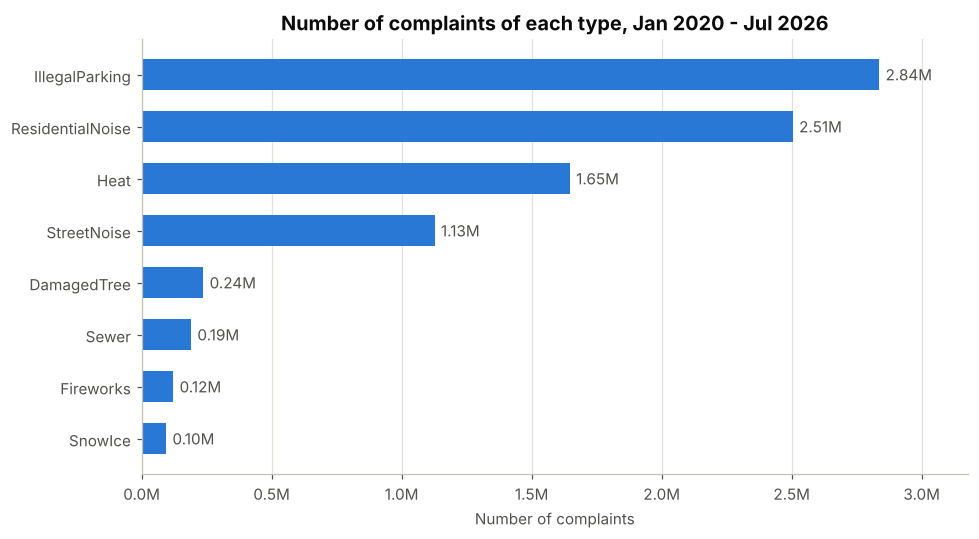

In [10]:
sorted_totals = totals.sort_values()     # smallest first, so the biggest bar ends up on top

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(sorted_totals.index, sorted_totals.values, color=BLUE, height=0.6)

labels = [f"{total / 1e6:.2f}M" for total in sorted_totals.values]
ax.bar_label(bars, labels=labels, padding=4, color=MUTED_INK)

ax.set_title("Number of complaints of each type, Jan 2020 - Jul 2026")
ax.set_xlabel("Number of complaints")
ax.xaxis.set_major_formatter(lambda value, position: f"{value / 1e6:.1f}M")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, sorted_totals.max() * 1.12)
plt.tight_layout()
plt.show()

## 5. Complaints vs. temperature

One graph per complaint type. Each dot is a day; the dark line is the average number of complaints
for each 5°F band of temperature (bands with fewer than 10 days are left off the line).

**Hiding the extreme days.** For **StreetNoise**, **ResidentialNoise**, **DamagedTree**, **Sewer**, and **Fireworks**, a few extreme days
stretch the y-axis so much that all the normal days get squashed at the bottom. For example, DamagedTree is usually around 60 complaints a day,
but it reached 13,955 on Aug 4, 2020 (Tropical Storm Isaias), and Fireworks reached 6,121 on July 4, 2020.
For these five graphs we zoom in: the y-axis stops at the **97th percentile**, so the busiest 3% of days (about 72 days)
are above the top of the chart. Those days are still used to calculate the average line and the correlation.

Heat, IllegalParking, and SnowIce are shown in full. Heat and IllegalParking have no extreme outliers, and for SnowIce the zoom
would cut off the average line on the coldest days, which is the pattern we want to see.

Every graph is also saved as its own PNG in the `figures` folder so it can be used on its own.

In [11]:
os.makedirs("figures", exist_ok=True)


def plot_temperature(column, hide_outliers=False):
    fig, ax = plt.subplots(figsize=(8, 5))

    # every day as a dot
    ax.scatter(daily["avg_temp_F"], daily[column], s=10, color=LIGHT_BLUE, alpha=0.5,
               edgecolors="none", label="One day")

    # average for each 5°F band (only bands with at least 10 days)
    temperature_band = (daily["avg_temp_F"] // 5) * 5 + 2.5      # middle of the band
    band_average = daily.groupby(temperature_band)[column].mean()
    band_days = daily.groupby(temperature_band)[column].size()
    band_average = band_average[band_days >= 10]
    ax.plot(band_average.index, band_average.values, color=DARK_BLUE, linewidth=2,
            marker="o", markersize=5, label="Average for each 5°F band")

    correlation = daily["avg_temp_F"].corr(daily[column])
    note = f"correlation r = {correlation:.2f}"

    if hide_outliers:
        # zoom in: the y-axis stops at the 97th percentile, so the busiest 3% of days are off the chart
        top = daily[column].quantile(0.97)
        ax.set_ylim(0, top)
        days_hidden = (daily[column] > top).sum()
        note = note + f"\n{days_hidden} busiest days are above the chart"
    else:
        ax.set_ylim(bottom=0)

    ax.set_title(f"{column}: complaints per day vs. temperature")
    ax.text(0.99, 0.97, note, transform=ax.transAxes, ha="right", va="top", color=MUTED_INK)
    ax.set_xlabel("Average daily temperature (°F, Central Park)")
    ax.set_ylabel("Complaints per day")
    ax.legend(loc="upper left")
    plt.tight_layout()

    fig.savefig(f"figures/temperature_{column}.png", dpi=150)
    plt.show()

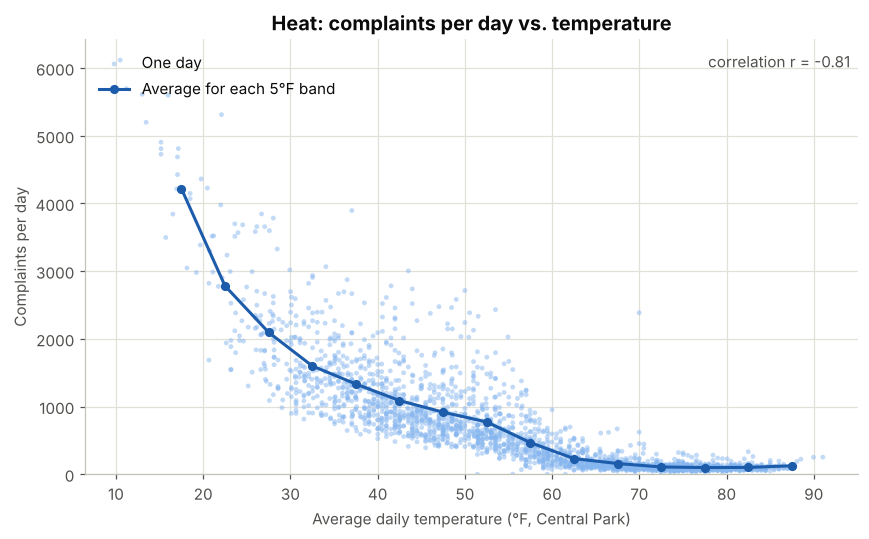

In [12]:
plot_temperature("Heat")

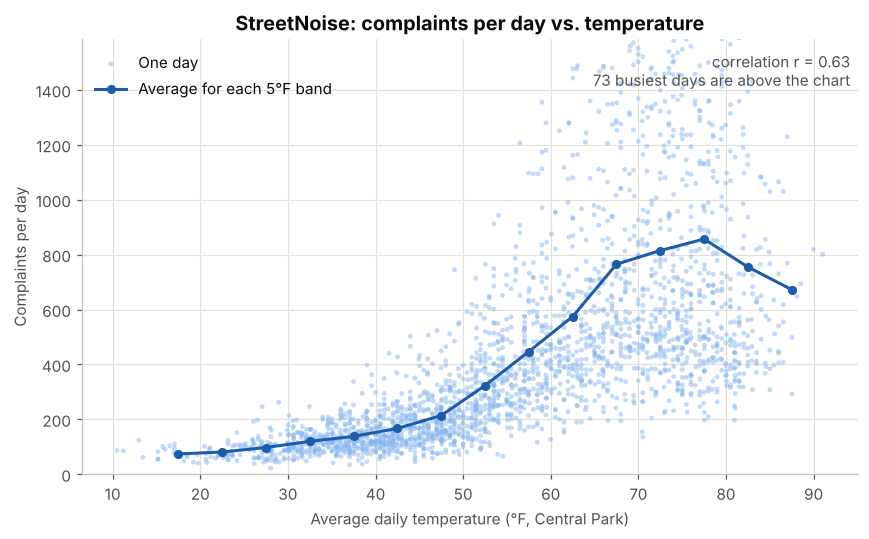

In [13]:
plot_temperature("StreetNoise", hide_outliers=True)

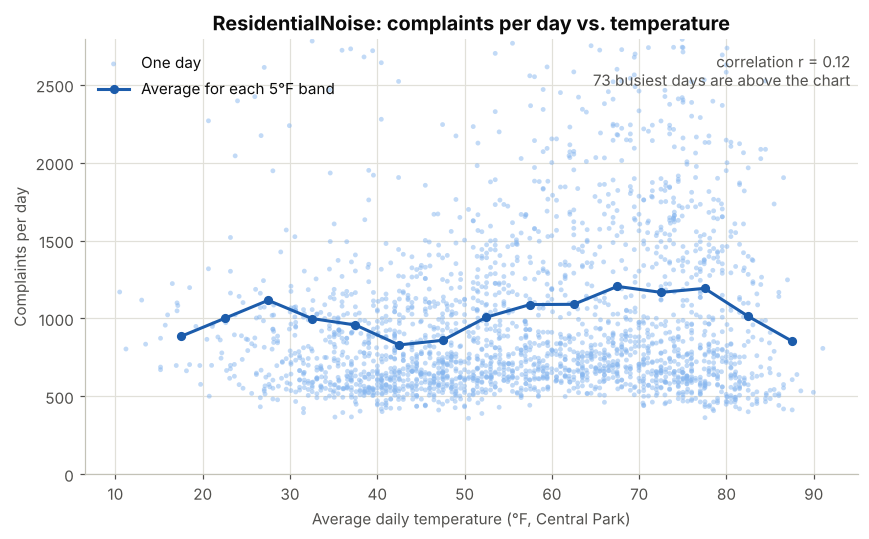

In [14]:
plot_temperature("ResidentialNoise", hide_outliers=True)

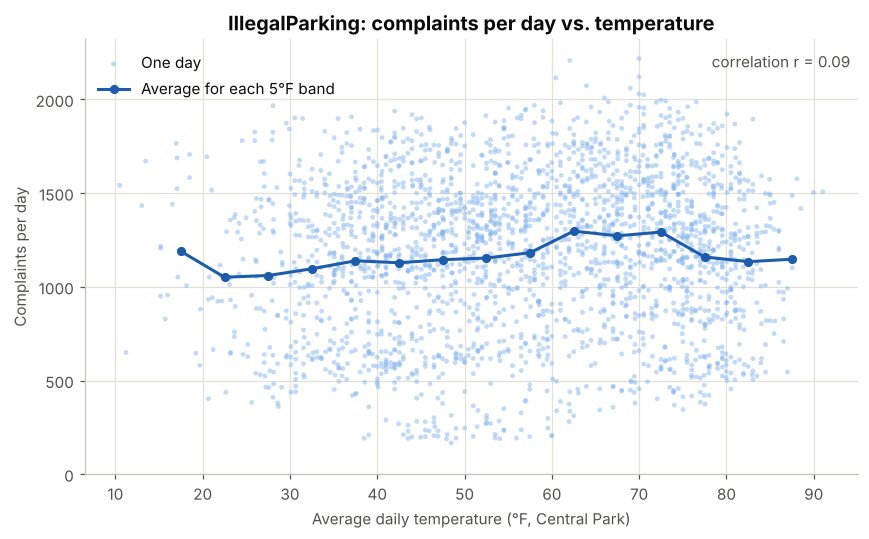

In [15]:
plot_temperature("IllegalParking")

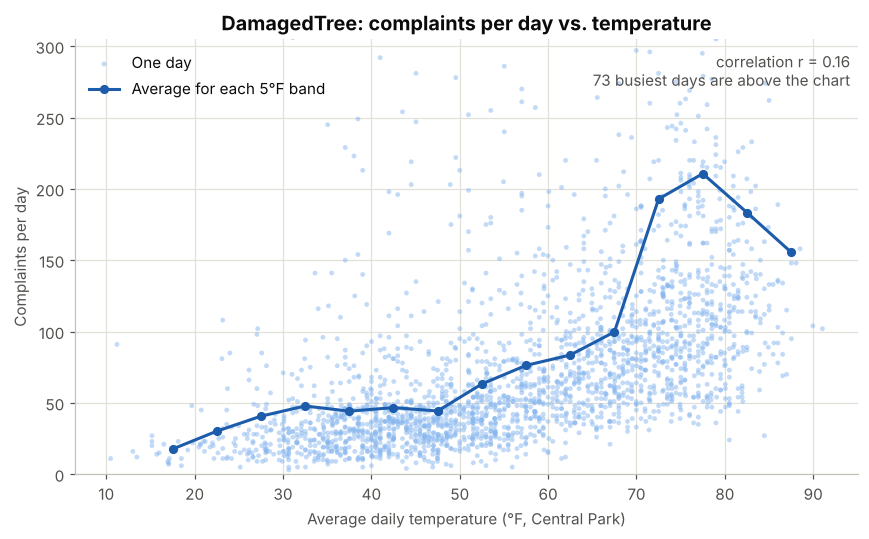

In [16]:
plot_temperature("DamagedTree", hide_outliers=True)

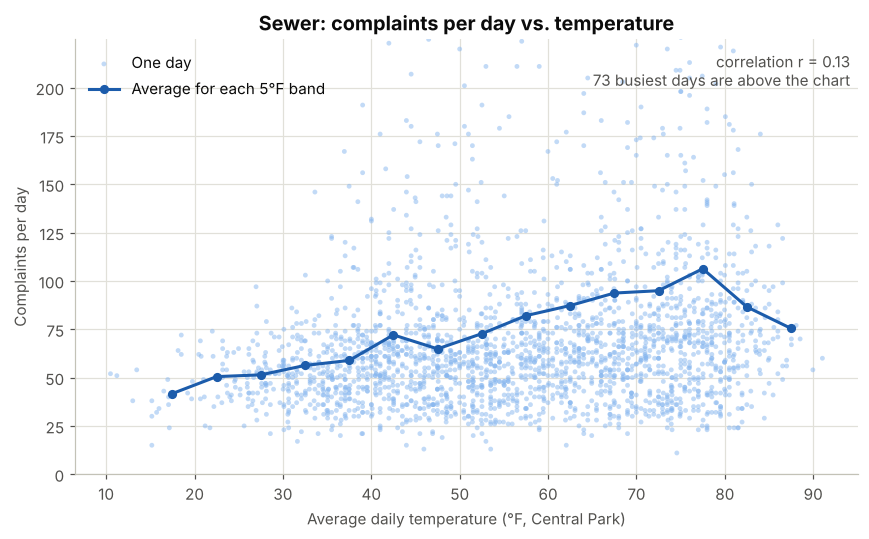

In [17]:
plot_temperature("Sewer", hide_outliers=True)

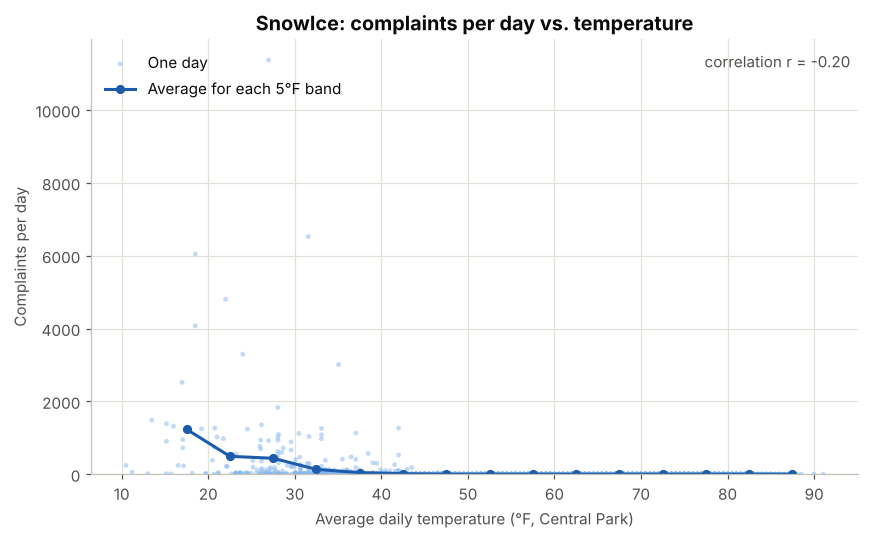

In [18]:
plot_temperature("SnowIce")

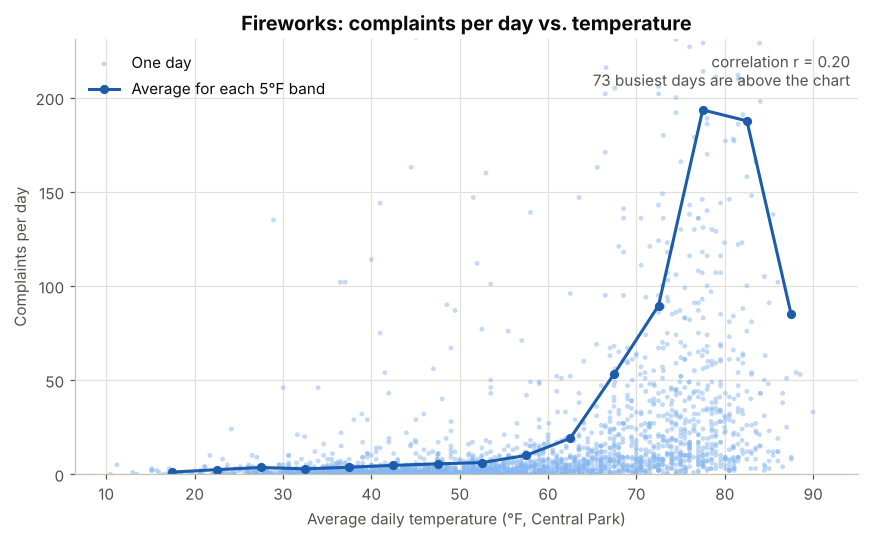

In [19]:
plot_temperature("Fireworks", hide_outliers=True)

## 6. Rate ratios

A **rate ratio** compares the average number of complaints per day in one group of days with a baseline:

$$\text{rate ratio} = \frac{\text{average complaints per day in the group}}{\text{average complaints per day in the baseline}}$$

* **1.00** means no difference, **1.25** means 25% more complaints per day, **0.80** means 20% fewer.

The heatmaps are drawn with **seaborn** (`sns.heatmap`), which does all the work in one line:

* `annot=True, fmt=".2f"` writes the rate ratio (2 decimals) in every cell.
* `cmap="coolwarm", center=1` colors the cells: 1 (no difference) is gray, **red = more complaints** than the baseline, **blue = fewer**.
* `vmin=0.5, vmax=1.5` uses the same color scale in every heatmap: 1.5 or more is the darkest red and 0.5 or less is the darkest blue.
  The number in the cell always shows the exact value.

These are simple comparisons: they do not adjust for other factors (for example, snow days are also winter days).
The XGBoost model in section 7 looks at all of the factors together.

In [20]:
def rate_ratio_table(group_column, reference=None):
    # average complaints per day for each group of days
    rates = daily.groupby(group_column)[TYPES].mean()

    # baseline: one group (if given) or the average over all days
    if reference is None:
        baseline = daily[TYPES].mean()
    else:
        baseline = rates.loc[reference]

    ratios = rates / baseline
    return ratios.T          # rows = complaint types, columns = groups


def plot_rate_ratio_heatmap(table, title, xlabel):
    plt.figure(figsize=(10, 5.5))
    sns.heatmap(table, annot=True, fmt=".2f", cmap="coolwarm", center=1, vmin=0.5, vmax=1.5,
                cbar_kws={"label": "Rate ratio"})
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("")
    plt.show()

### 6a. Weather condition

Baseline: **normal-weather days** (`is_normal_weather` = 1, so none of the six conditions).
Each column compares the days that have one condition with the normal-weather days.
Because each condition has its own column, a day can be counted in more than one column
(for example, a snowy day with a high below 32°F is in both **Snow** and **Freezing**).

In [21]:
normal_days = daily[daily["is_normal_weather"] == 1]

weather_ratios = pd.DataFrame()
for condition in WEATHER_CONDITIONS:
    condition_days = daily[daily[condition] == 1]
    weather_ratios[condition] = condition_days[TYPES].mean() / normal_days[TYPES].mean()

weather_ratios.round(2)

,is_snow,is_freezing,is_heavy_rain,is_rain,is_windy,is_hot
Heat,2.85,4.86,0.89,0.82,2.00,0.18
StreetNoise,0.20,0.16,0.57,0.71,0.46,1.42
ResidentialNoise,0.96,0.96,0.82,0.88,0.90,0.89
IllegalParking,0.85,0.89,0.88,0.93,0.96,0.94
DamagedTree,0.77,0.40,2.49,1.88,4.51,2.32
Sewer,0.85,0.75,5.04,1.64,1.94,1.37
SnowIce,31.72,64.29,0.04,0.08,10.25,0.00
Fireworks,0.11,0.04,0.34,1.15,0.62,3.74


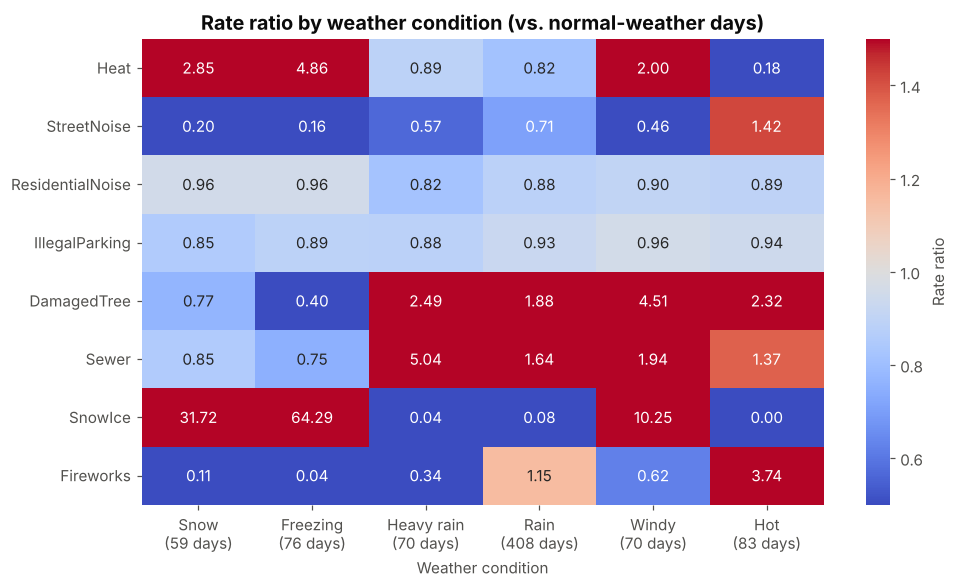

In [22]:
# nicer column names that also show the number of days, e.g. "Snow (59 days)"
condition_names = ["Snow", "Freezing", "Heavy rain", "Rain", "Windy", "Hot"]
days_per_condition = daily[WEATHER_CONDITIONS].sum()
weather_ratios.columns = [f"{name}\n({days} days)" for name, days in zip(condition_names, days_per_condition)]

plot_rate_ratio_heatmap(
    weather_ratios,
    title="Rate ratio by weather condition (vs. normal-weather days)",
    xlabel="Weather condition",
)

### 6b. Day of the week

Baseline: the **average day**, so 1.10 means a typical Monday (for example) has 10% more complaints than the average day.

In [23]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday_ratios = rate_ratio_table("day_name")[weekday_order]
weekday_ratios.round(2)

day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Heat,1.11,1.08,0.99,0.95,0.94,0.96,0.97
StreetNoise,0.80,0.66,0.66,0.71,0.98,1.52,1.67
ResidentialNoise,0.87,0.76,0.72,0.73,0.90,1.47,1.55
IllegalParking,1.01,1.04,1.02,1.04,1.02,0.92,0.97
DamagedTree,1.13,1.42,1.18,1.02,0.98,0.66,0.61
Sewer,1.14,1.09,1.05,1.22,1.13,0.71,0.65
SnowIce,1.74,2.00,1.09,0.69,0.44,0.39,0.65
Fireworks,0.87,0.72,0.63,0.73,0.92,1.57,1.57


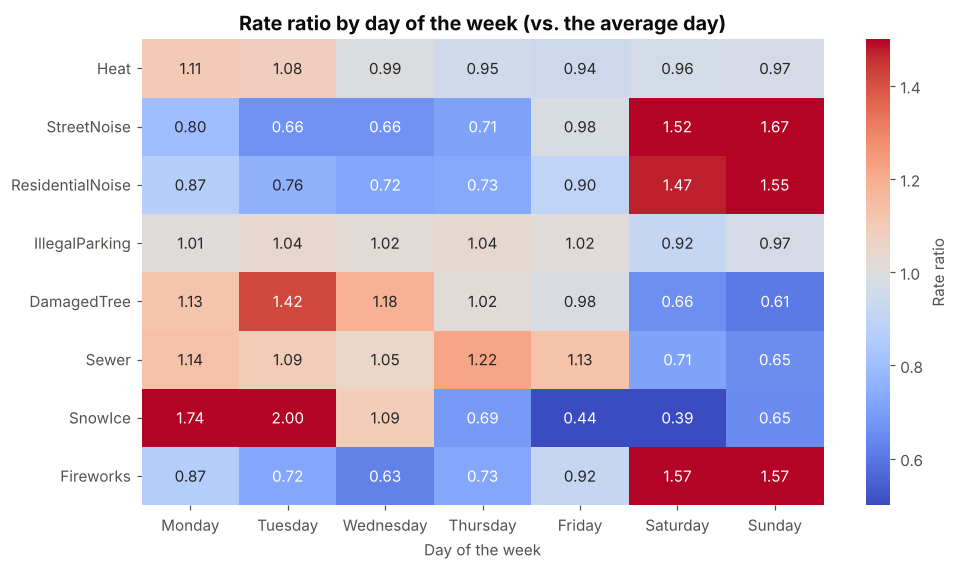

In [24]:
plot_rate_ratio_heatmap(
    weekday_ratios,
    title="Rate ratio by day of the week (vs. the average day)",
    xlabel="Day of the week",
)

### 6c. Holiday vs. not a holiday

Holidays are the federal holidays flagged in the data (`IS_HOLIDAY`): New Year's Day, MLK Day, Presidents' Day, Memorial Day,
Juneteenth, Independence Day, Labor Day, Columbus Day, Veterans Day, Thanksgiving, and Christmas.

We compare the average holiday with two baselines:
1. **all other days** (every day that is not a holiday), and
2. **ordinary weekdays** (Monday - Friday days that are not holidays). This is a fairer comparison, because every holiday in the data
   falls on a weekday, while "all other days" also includes the weekends.

In [25]:
holidays = daily[daily["is_holiday"] == 1]
other_days = daily[daily["is_holiday"] == 0]
ordinary_weekdays = daily[(daily["is_holiday"] == 0) & (daily["is_weekend"] == 0)]

holiday_ratios = pd.DataFrame({
    "vs. all other days": holidays[TYPES].mean() / other_days[TYPES].mean(),
    "vs. ordinary weekdays": holidays[TYPES].mean() / ordinary_weekdays[TYPES].mean(),
})
holiday_ratios.round(2)

,vs. all other days,vs. ordinary weekdays
Heat,1.15,1.14
StreetNoise,1.24,1.65
ResidentialNoise,1.20,1.53
IllegalParking,0.85,0.82
DamagedTree,0.87,0.75
Sewer,0.76,0.67
SnowIce,0.87,0.72
Fireworks,5.45,8.06


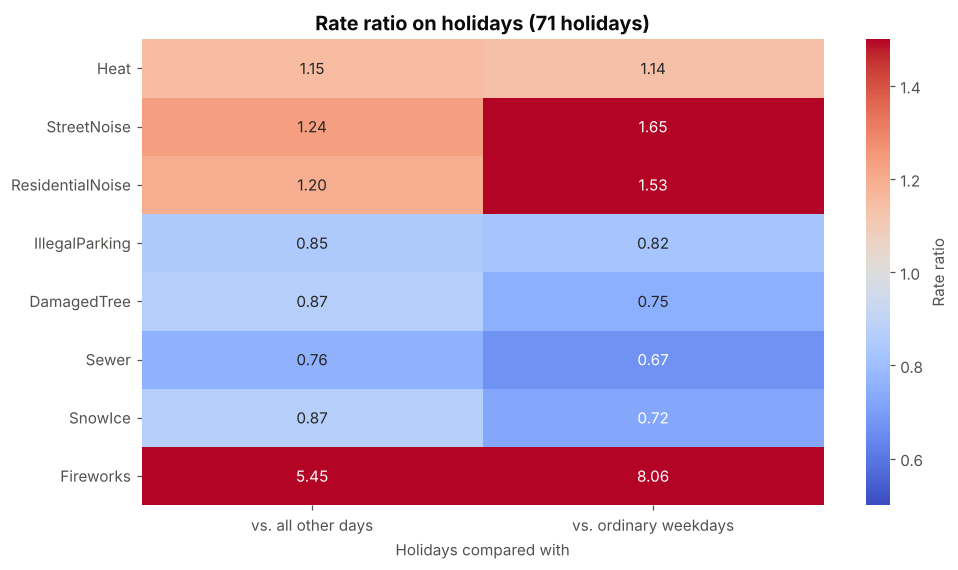

In [26]:
plot_rate_ratio_heatmap(
    holiday_ratios,
    title=f"Rate ratio on holidays ({len(holidays)} holidays)",
    xlabel="Holidays compared with",
)

In [27]:
print("Holidays by day of the week:", holidays["day_name"].value_counts().to_dict())

winter_months = [11, 12, 1, 2]
print(f"Days that are in Nov - Feb: {holidays['month'].isin(winter_months).mean():.0%} of holidays, "
      f"{other_days['month'].isin(winter_months).mean():.0%} of other days")

# the 5 holidays with the most fireworks complaints
holidays.nlargest(5, "Fireworks")[["date", "day_name", "Fireworks"]]

Holidays by day of the week: {'Monday': 42, 'Friday': 11, 'Thursday': 11, 'Wednesday': 5, 'Tuesday': 2}
Days that are in Nov - Feb: 55% of holidays, 32% of other days


,date,day_name,Fireworks
2011,2025-07-04,Friday,3134
1280,2023-07-04,Tuesday,2759
1646,2024-07-04,Thursday,2746
915,2022-07-04,Monday,2232
551,2021-07-05,Monday,1721


**How to read the holiday results**

Each cell compares the average holiday with a baseline: red means more complaints on holidays, blue means fewer.
All 71 holidays fall on a weekday (42 of them are Mondays), so the second column, which compares them with ordinary weekdays only, is the fairer one.

* **Fireworks has by far the biggest holiday effect (5.45×), and it is almost all July 4th.** The five holidays with the most fireworks complaints
  (table above) are all Independence Day. Compared with ordinary weekdays, holidays have 8× as many fireworks complaints.
* **Noise works like a weekend.** StreetNoise (1.24) and ResidentialNoise (1.20) go up on holidays because people are off work, at home,
  and celebrating. Compared with ordinary weekdays the effect is bigger (1.65 and 1.53), almost the same as a Saturday or Sunday in section 6b.
* **Complaints that people report during the work week go down.** Sewer (0.76), DamagedTree (0.87), and IllegalParking (0.85) are lower on holidays,
  and lower still compared with ordinary weekdays (0.67, 0.75, and 0.82). Sewer and DamagedTree also drop on weekends (6b),
  so a holiday looks like a weekend day for them: fewer people are out commuting to notice and report problems.
* **Heat (1.15) comes from the season, not the holiday.** 55% of holidays are in November - February (New Year's, MLK Day, Presidents' Day,
  Veterans Day, Thanksgiving, Christmas), compared with 32% of other days, and heat complaints are about twice the average in those months (section 6d).
  The two columns give almost the same number for Heat (1.15 and 1.14) because heat complaints barely depend on the day of the week.
* **SnowIce (0.87)** depends on whether a snowstorm happened to land on a holiday, so with only 71 holidays this number doesn't say much.

### 6d. Month

Baseline: the **average day** across the whole data set.
(January - July include 2026, August - December do not.)

In [28]:
month_ratios = rate_ratio_table("month")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_ratios.columns = month_names
month_ratios.round(2)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Heat,2.36,1.79,1.13,0.75,0.35,0.16,0.14,0.12,0.18,1.01,1.88,2.22
StreetNoise,0.26,0.28,0.54,0.78,1.37,1.91,1.70,1.60,1.48,1.11,0.62,0.34
ResidentialNoise,0.94,0.80,0.79,0.87,1.13,1.06,1.07,1.03,1.28,1.10,0.95,1.03
IllegalParking,0.92,0.95,1.02,0.98,1.07,1.10,0.98,0.92,1.07,1.03,1.01,0.95
DamagedTree,0.34,0.45,0.49,0.57,0.88,1.45,1.68,3.33,1.10,0.79,0.57,0.48
Sewer,0.77,0.73,0.91,0.82,1.01,0.96,1.30,1.19,1.80,1.03,0.77,0.79
SnowIce,4.32,5.63,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,1.82
Fireworks,0.14,0.06,0.06,0.09,0.32,4.33,5.47,0.32,0.24,0.16,0.12,0.11


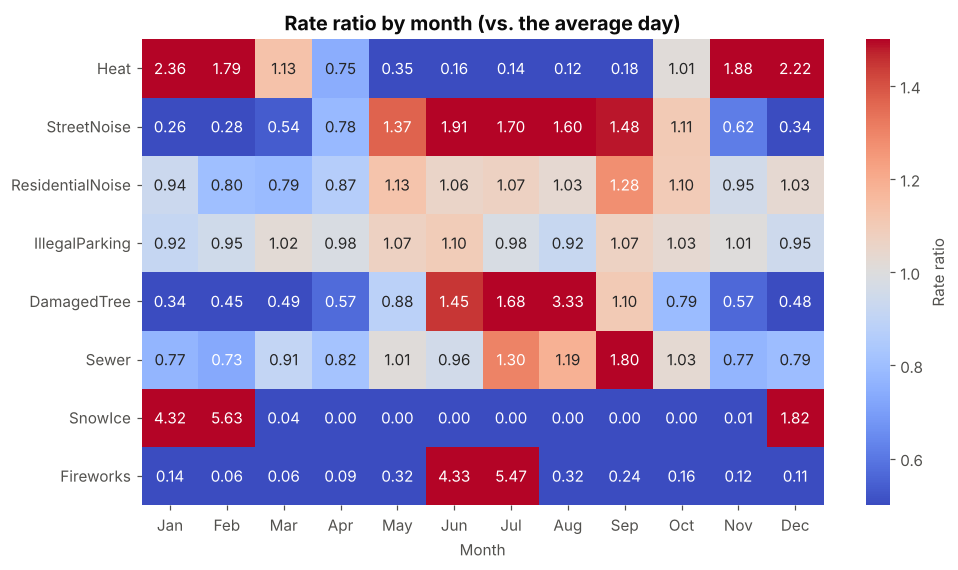

In [29]:
plot_rate_ratio_heatmap(
    month_ratios,
    title="Rate ratio by month (vs. the average day)",
    xlabel="Month",
)

## 7. XGBoost: predict each complaint type's daily count

We train **one XGBoost model per complaint type** (8 models). Each model gets the same information about a day:

* **Weather:** temperature (average, high, low), precipitation, snowfall, snow on the ground, wind, gusts,
  yesterday's precipitation and snowfall, and the **six 0/1 weather condition columns** from section 3
  (`is_snow`, `is_freezing`, `is_heavy_rain`, `is_rain`, `is_windy`, `is_hot`)
* **Calendar:** day of the week, month, day of the year, weekend, holiday, and year (311 use changes over time)

To test the models fairly, we train on the earlier days and test on the **last 365 days**, which the models never see while training.

Because we are predicting **counts**, the models use XGBoost's Poisson objective (`count:poisson`).
It is built for count data and keeps the models from over-reacting to a few extreme days in the training data.

In [30]:
# yesterday's weather can matter too (for example, snow that fell overnight)
daily["precip_yesterday_in"] = daily["precip_in"].shift(1)
daily["snowfall_yesterday_in"] = daily["snowfall_in"].shift(1)

FEATURES = [
    "avg_temp_F", "max_temp_F", "min_temp_F",
    "precip_in", "trace_precip", "snowfall_in", "trace_snow", "snow_depth_in",
    "avg_wind_mph", "max_gust_mph",
    "precip_yesterday_in", "snowfall_yesterday_in",
    "is_snow", "is_freezing", "is_heavy_rain", "is_rain", "is_windy", "is_hot",
    "day_of_week", "month", "day_of_year", "is_weekend", "is_holiday", "year",
]

test_start = daily["date"].max() - pd.Timedelta(days=364)
train = daily[daily["date"] < test_start]
test = daily[daily["date"] >= test_start]

print(f"Training days: {len(train)}  ({train['date'].min().date()} to {train['date'].max().date()})")
print(f"Testing days:  {len(test)}  ({test['date'].min().date()} to {test['date'].max().date()})")

Training days: 2037  (2020-01-01 to 2025-07-29)
Testing days:  365  (2025-07-30 to 2026-07-29)


In [31]:
models = {}
predictions = pd.DataFrame({"date": test["date"]})
scores = []

for complaint_type in TYPES:
    model = XGBRegressor(
        objective="count:poisson",     # made for predicting counts
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        importance_type="gain",
        random_state=42,
    )
    model.fit(train[FEATURES], train[complaint_type])

    predicted = model.predict(test[FEATURES])
    predictions[complaint_type] = predicted
    models[complaint_type] = model

    actual = test[complaint_type]
    scores.append({
        "complaint type": complaint_type,
        "average per day (test)": actual.mean(),
        "MAE": mean_absolute_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    })

scores = pd.DataFrame(scores).set_index("complaint type")
scores["MAE as % of average"] = 100 * scores["MAE"] / scores["average per day (test)"]
scores.round(2)

,average per day (test),MAE,R²,MAE as % of average
complaint type,,,,
Heat,978.17,165.35,0.92,16.90
StreetNoise,482.29,72.85,0.91,15.10
ResidentialNoise,1201.11,365.17,-0.18,30.40
IllegalParking,1665.38,157.02,0.16,9.43
DamagedTree,112.13,52.80,0.25,47.09
Sewer,86.24,32.64,0.24,37.84
SnowIce,175.16,140.19,0.14,80.04
Fireworks,30.59,17.26,0.65,56.42


**How to read this:** MAE (mean absolute error) is how many complaints the prediction is off by on a typical day.
R² is the share of the day-to-day variation the model explains (1 = perfect, 0 = no better than guessing the average).

### Predict a given day

`predict_day` returns the model's prediction for every complaint type on one date, next to what actually happened.
Below it is used on three test-set days the models never saw: the snowiest, the wettest, and the hottest.

In [32]:
def predict_day(date):
    day = daily[daily["date"] == pd.Timestamp(date)]
    result = pd.DataFrame(index=TYPES)
    result["predicted"] = [models[complaint_type].predict(day[FEATURES])[0] for complaint_type in TYPES]
    result["actual"] = day[TYPES].iloc[0].values
    return result.round(0).astype(int)


example_days = {
    "Snowiest day": test.loc[test["snowfall_in"].idxmax(), "date"],
    "Wettest day": test.loc[test["precip_in"].idxmax(), "date"],
    "Hottest day": test.loc[test["max_temp_F"].idxmax(), "date"],
}

for label, date in example_days.items():
    day = daily[daily["date"] == date].iloc[0]
    print(f"{label}: {date.date()} ({day['day_name']}) - snow {day['snowfall_in']:.1f} in, "
          f"precipitation {day['precip_in']:.2f} in, high {day['max_temp_F']:.0f}°F")
    display(predict_day(date))

Snowiest day: 2026-01-25 (Sunday) - snow 11.4 in, precipitation 1.80 in, high 22°F


,predicted,actual
Heat,4272,5601
StreetNoise,87,91
ResidentialNoise,1434,1023
IllegalParking,1000,956
DamagedTree,42,15
Sewer,55,34
SnowIce,85,1315
Fireworks,3,1


Wettest day: 2025-10-30 (Thursday) - snow 0.0 in, precipitation 1.83 in, high 63°F


,predicted,actual
Heat,840,1378
StreetNoise,183,245
ResidentialNoise,1116,718
IllegalParking,1427,1482
DamagedTree,160,482
Sewer,344,1698
SnowIce,0,0
Fireworks,5,2


Hottest day: 2026-07-02 (Thursday) - snow 0.0 in, precipitation 0.00 in, high 100°F


,predicted,actual
Heat,151,252
StreetNoise,662,801
ResidentialNoise,551,808
IllegalParking,1409,1508
DamagedTree,139,102
Sewer,64,60
SnowIce,0,0
Fireworks,93,257


## 8. Most important features

XGBoost measures how much each feature improves the model's predictions (**gain**).
The importances for each model add up to 1.
Features that carry similar information (like the three temperature columns, or month and day of year)
share the credit between them.

In [33]:
importance = pd.DataFrame(
    {complaint_type: models[complaint_type].feature_importances_ for complaint_type in TYPES},
    index=FEATURES,
)
importance.round(3)

,Heat,StreetNoise,ResidentialNoise,IllegalParking,DamagedTree,Sewer,SnowIce,Fireworks
avg_temp_F,0.353,0.177,0.033,0.011,0.030,0.011,0.048,0.226
max_temp_F,0.369,0.236,0.033,0.011,0.017,0.010,0.051,0.191
min_temp_F,0.075,0.024,0.039,0.017,0.113,0.021,0.040,0.055
precip_in,0.004,0.031,0.027,0.018,0.019,0.105,0.007,0.006
trace_precip,0.009,0.008,0.012,0.006,0.019,0.004,0.006,0.003
snowfall_in,0.004,0.001,0.017,0.016,0.002,0.003,0.019,0.001
trace_snow,0.002,0.001,0.011,0.003,0.002,0.001,0.011,0.001
snow_depth_in,0.004,0.002,0.010,0.045,0.004,0.001,0.644,0.001
avg_wind_mph,0.006,0.008,0.019,0.010,0.010,0.010,0.010,0.017
max_gust_mph,0.007,0.009,0.020,0.005,0.100,0.019,0.005,0.011


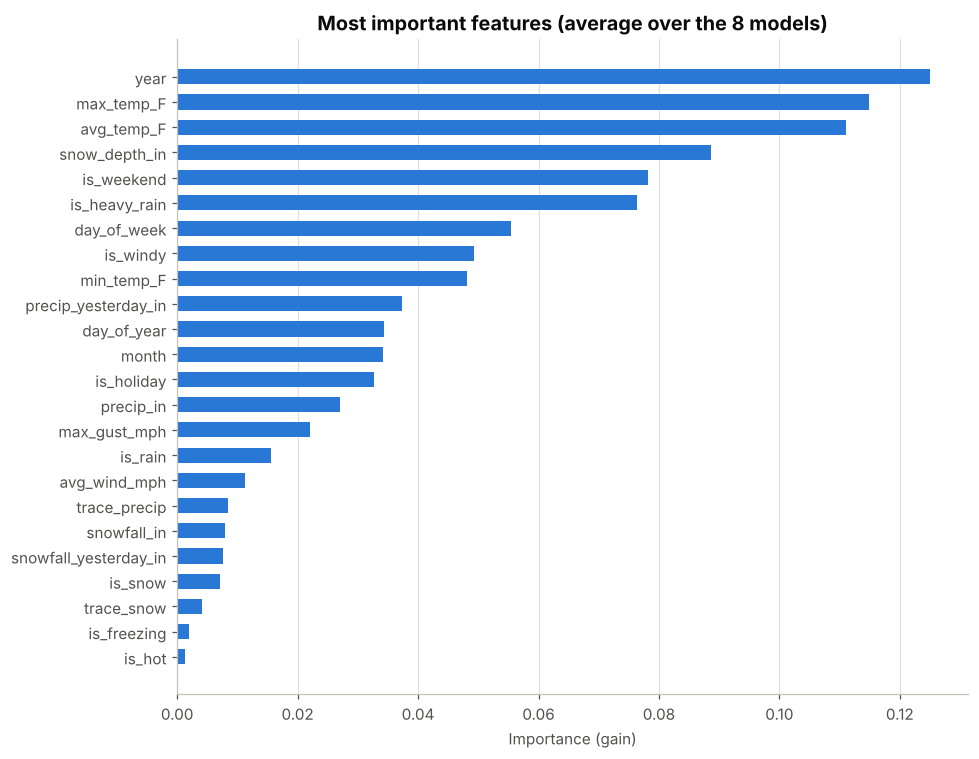

In [34]:
# Average importance across the 8 models
average_importance = importance.mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(average_importance.index, average_importance.values, color=BLUE, height=0.6)
ax.set_title("Most important features (average over the 8 models)")
ax.set_xlabel("Importance (gain)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

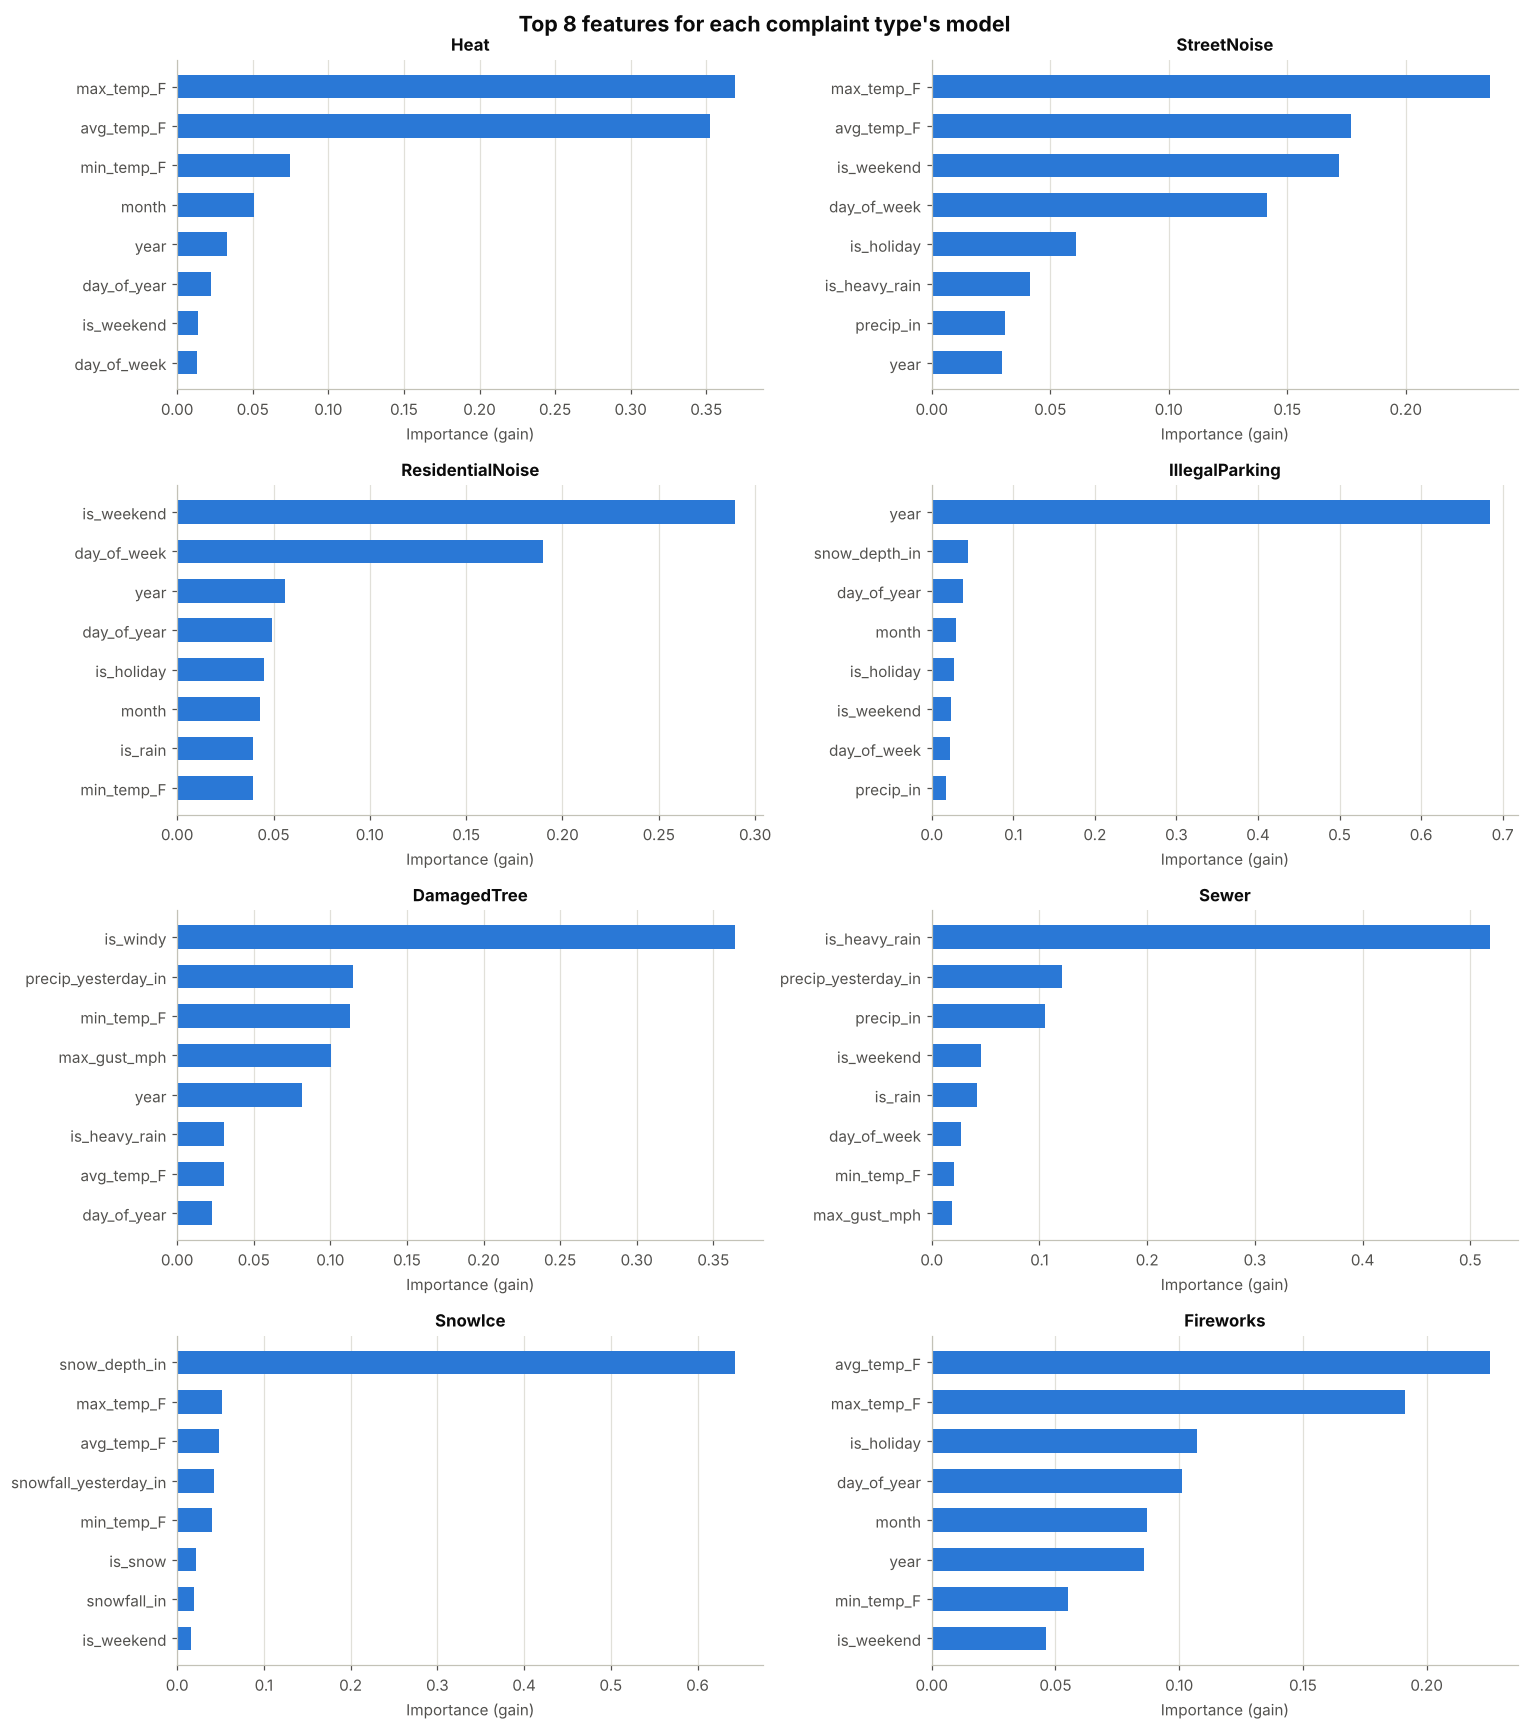

In [35]:
# Top 8 features for each complaint type's model
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, complaint_type in zip(axes.flat, TYPES):
    top_features = importance[complaint_type].sort_values().tail(8)
    ax.barh(top_features.index, top_features.values, color=BLUE, height=0.6)
    ax.set_title(complaint_type, fontsize=11)
    ax.set_xlabel("Importance (gain)")
    ax.grid(axis="y", visible=False)

fig.suptitle("Top 8 features for each complaint type's model", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Key takeaways

**How many:** Together the 8 types are 40% of the 21.9 million complaints from Jan 2020 to Jul 2026. IllegalParking (13.0%) and
ResidentialNoise (11.4%) are the biggest. The storm-related types are much smaller: DamagedTree 1.1%, Sewer 0.9%, Fireworks 0.6%, SnowIce 0.4%.

**Temperature**
* **Heat** is by far the most temperature-driven type (r = −0.81): about 4,200 complaints a day at 15–20°F, compared with about 100 a day above 70°F.
* **StreetNoise** rises strongly in warm weather (r = 0.63), from under 100 a day below 25°F to about 850 a day at 75–80°F.
* **DamagedTree** goes from about 20–40 a day below 30°F to about 200 a day at 70–85°F, and **SnowIce** only shows up below about 40°F.
  Their correlations are weak (0.16 and −0.20) because most of their complaints come on a few storm days.
* **ResidentialNoise** (r = 0.12), **IllegalParking** (0.09), and **Sewer** (0.13) barely change with temperature.

**Weather conditions** (vs. normal-weather days)
* Each storm type reacts to the weather we expected. **SnowIce**: 64× on freezing days and 32× on snow days. **Sewer**: 5.0× on heavy-rain days
  and 1.6× on rainy days. **DamagedTree**: 4.5× on windy days and 2.5× on heavy-rain days.
* **Heat** is 4.9× on freezing days, 2.9× on snow days, and 2.0× on windy days (most windy days are in the winter). Hot days bring only 0.18×.
* **Fireworks** (3.7×) and **StreetNoise** (1.4×) go up on hot days. StreetNoise falls 80–84% on snowy and freezing days.
* **ResidentialNoise** and **IllegalParking** barely react to the weather (0.82–0.96), so they are mostly driven by the calendar.

**Day of the week:** StreetNoise, ResidentialNoise, and Fireworks are weekend complaints (about 1.5–1.7× on Saturday and Sunday).
DamagedTree and Sewer drop 29–39% on weekends. Heat and IllegalParking barely change. SnowIce jumps around because it depends on which days the few big storms fell on.

**Holidays:** Fireworks is 5.5× on holidays, almost all from July 4th. Both Noise types rise about 20% (like a weekend),
and Sewer, DamagedTree, and IllegalParking fall 13–24%. Heat is 15% higher only because most holidays are in the winter months (section 6c).

**Month:** Heat ranges from 2.36× in January to 0.12× in August, and SnowIce only appears from December to February.
Fireworks is 4–5× in June and July and below 0.35× in every other month. DamagedTree peaks in August (3.3×, including Tropical Storm Isaias in Aug 2020),
and Sewer peaks in September (1.8×, including the remains of Hurricane Ida in Sept 2021).

**XGBoost model**
* It works well for the types with a smooth seasonal pattern: **Heat** (R² = 0.92), **StreetNoise** (0.91), and **Fireworks** (0.65).
* The storm types are hard to predict (DamagedTree 0.25, Sewer 0.24, SnowIce 0.14). The model gets the direction right, but it badly underestimates the
  biggest storms. For example, on Oct 30, 2025 (1.83 inches of rain) it predicted 344 sewer complaints and there were 1,698, and on the snowiest
  test day it predicted 85 SnowIce complaints and there were 1,315. A few storms like these make up a big part of these types' complaints.
* **IllegalParking** (0.16) grows every year (about 530 a day in 2020 to 1,720 in 2026), and a tree model cannot predict levels higher than anything
  it was trained on. On a typical day it is still only off by about 9%.
* **ResidentialNoise** (−0.18) had bursts in fall 2025 that the model did not predict, and the model predicted a big New Year's spike
  (based on earlier years) that did not happen.

**Most important features:** For these 8 types, weather matters about as much as the calendar. Overall the top features are `year`,
the temperature columns, `snow_depth_in`, and `is_weekend`.
* **The 0/1 weather condition columns are the top features for two of the storm types:** `is_heavy_rain` has 52% of Sewer's importance,
  and `is_windy` is DamagedTree's top feature (36%). This makes the models easy to read ("heavy rain drives sewer complaints").
  They don't add new information, though: each one is built from a raw weather column the model already has (for example, `is_heavy_rain` is
  `precip_in` ≥ 1 with no snow), so a tree could make the same split by itself.
* **SnowIce** depends mostly on **snow on the ground** (`snow_depth_in`, 64%), not on the snowfall that day: people report snow and ice in the days after a storm.
* **Heat** depends mostly on temperature (80%), **ResidentialNoise** on the weekend and day of the week (48%), and **IllegalParking** on the year (69%).

*Caveat:* the rate ratios are simple comparisons that don't adjust for other factors. For example, part of the "snow" effect
is really a "winter" effect.

## 10. Evaluation of significance

**Our preregistered hypotheses (Phase 2)**

| | Hypothesis | Preregistered test | Null hypothesis H₀ | Alternative H_A |
|---|---|---|---|---|
| **H1** | Colder temperatures are associated with more 311 reports | OLS: total reports per day ~ average temperature (Central Park) | β_temperature ≥ 0 | β_temperature < 0 |
| **H2** | Thunder is associated with more 311 reports | OLS: total reports per day ~ thunder indicator (Central Park) | β_thunder ≤ 0 | β_thunder > 0 |

**How we test them**

* Both hypotheses name a direction, so we use **one-sided t-tests** on the regression slope at **α = 0.05**.
* The outcome is the **total number of 311 reports per day** (the `All complaints` series in `data/daily_complaints_weather.csv`, which leaves out the COVID-only types).
  We use the same study period as the rest of this notebook (Jan 1, 2020 – Jul 29, 2026; see section 3).
* **Robustness checks (clearly labeled extensions, not the preregistered test):**
  1. *Newey-West (HAC) standard errors.* Ordinary regression p-values assume every day is independent, but 311 volume on one day is strongly related to the days around it.
     HAC standard errors allow for that correlation (up to 7 days apart), which makes the p-values more honest.
  2. *Calendar controls* (day of the week, holiday, year), which our Phase 2 reviewers asked about. 311 volume grows every year and has a strong weekly cycle (section 6b).
  3. *Snowfall as a control* (reviewer question 2), *a squared temperature term* (question 3), *the JFK station* (question 4), and *next-day thunder* (question 5).
* Section 10c adds significance tests for the complaint-type rate ratios in section 6a, with a correction for running many tests at once.

In [36]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

ALPHA = 0.05

# The preregistered hypotheses are about the TOTAL number of 311 reports per day, so they use the
# "All complaints" series from our cleaned data set (written by the data cleaning notebook, nyc_311_weather_analysis.ipynb).
cleaned = pd.read_csv("data/daily_complaints_weather.csv", parse_dates=["DATE"])
totals_daily = cleaned[(cleaned["COMPLAINT_GROUP"] == "All complaints") & (cleaned["DATE"] <= END_DATE)].copy()
totals_daily = totals_daily.sort_values("DATE").reset_index(drop=True)

# yesterday's thunder (for the next-day check in 10b)
totals_daily["CP_THUNDER_YESTERDAY"] = totals_daily["CP_WT_THUNDER"].shift(1)

print(f"{len(totals_daily)} days, {totals_daily['DATE'].min().date()} to {totals_daily['DATE'].max().date()}")
print(f"Average total reports per day: {totals_daily['REQUESTS'].mean():,.0f}")
print(f"Thunder days: Central Park {totals_daily['CP_WT_THUNDER'].sum()}, JFK {totals_daily['JFK_WT_THUNDER'].sum()}")


def one_sided_p(model, variable, direction):
    """One-sided p-value for H_A: beta < 0 (direction='negative') or beta > 0 (direction='positive')."""
    beta = model.params[variable]
    two_sided = model.pvalues[variable]
    in_predicted_direction = beta < 0 if direction == "negative" else beta > 0
    return two_sided / 2 if in_predicted_direction else 1 - two_sided / 2


def coefficient_row(label, model, variable, direction):
    low, high = model.conf_int().loc[variable]
    return {
        "model": label,
        "coefficient (reports/day)": model.params[variable],
        "95% CI low": low,
        "95% CI high": high,
        "t": model.tvalues[variable],
        "one-sided p": one_sided_p(model, variable, direction),
        "R²": model.rsquared,
    }


# Robust standard errors: neighbouring days are not independent (a busy week is followed by a busy week),
# so we also report Newey-West (HAC) standard errors that allow for correlation up to 7 days apart.
HAC = dict(cov_type="HAC", cov_kwds={"maxlags": 7})
CALENDAR = "C(DAY_OF_WEEK) + IS_HOLIDAY + C(YEAR)"

2402 days, 2020-01-01 to 2026-07-29
Average total reports per day: 9,116
Thunder days: Central Park 180, JFK 192


### 10a. Hypothesis 1: colder temperatures → more 311 reports

The first row of the table below is the preregistered test. The slope is the change in total reports per day for each 1°F increase in average temperature,
so H1 predicts a **negative** slope.

In [37]:
h1_models = {
    "Preregistered: OLS, temperature only": smf.ols("REQUESTS ~ CP_TAVG", totals_daily).fit(),
    "Same model, HAC (Newey-West) errors": smf.ols("REQUESTS ~ CP_TAVG", totals_daily).fit(**HAC),
    "Extension: + weekday, holiday, year (HAC)": smf.ols(f"REQUESTS ~ CP_TAVG + {CALENDAR}", totals_daily).fit(**HAC),
    # reviewer question 2: does snowfall explain part of the temperature relationship?
    "Extension: + snowfall, weekday, holiday, year (HAC)":
        smf.ols(f"REQUESTS ~ CP_TAVG + CP_SNOW + {CALENDAR}", totals_daily).fit(**HAC),
}
h1_table = pd.DataFrame([coefficient_row(label, model, "CP_TAVG", "negative") for label, model in h1_models.items()])
h1_table.set_index("model").round({"coefficient (reports/day)": 1, "95% CI low": 1, "95% CI high": 1,
                                   "t": 2, "one-sided p": 4, "R²": 3})

,coefficient (reports/day),95% CI low,95% CI high,t,one-sided p,R²
model,,,,,,
"Preregistered: OLS, temperature only",22.8,18.6,27.0,10.58,1.0000,0.045
"Same model, HAC (Newey-West) errors",22.8,10.9,34.7,3.76,0.9999,0.045
"Extension: + weekday, holiday, year (HAC)",24.8,15.8,33.8,5.40,1.0000,0.358
"Extension: + snowfall, weekday, holiday, year (HAC)",24.8,15.8,33.9,5.40,1.0000,0.358


In [38]:
# Reviewer question 3: is the relationship nonlinear? Add a squared temperature term.
h1_quadratic = smf.ols(f"REQUESTS ~ CP_TAVG + I(CP_TAVG ** 2) + {CALENDAR}", totals_daily).fit(**HAC)
b1 = h1_quadratic.params["CP_TAVG"]
b2 = h1_quadratic.params["I(CP_TAVG ** 2)"]
print(f"Linear term:  {b1:8.2f}   p = {h1_quadratic.pvalues['CP_TAVG']:.1e}")
print(f"Squared term: {b2:8.3f}   p = {h1_quadratic.pvalues['I(CP_TAVG ** 2)']:.1e}")
print(f"The curve is U-shaped, with its lowest point at about {-b1 / (2 * b2):.0f}°F")

snow_model = h1_models["Extension: + snowfall, weekday, holiday, year (HAC)"]
low, high = snow_model.conf_int().loc["CP_SNOW"]
print(f"Snowfall (with temperature and calendar held fixed): {snow_model.params['CP_SNOW']:+.0f} reports per inch "
      f"(95% CI {low:.0f} to {high:.0f}, p = {snow_model.pvalues['CP_SNOW']:.2g})")

# average total reports for each 10°F band (bands with at least 10 days)
band = (totals_daily["CP_TAVG"] // 10) * 10
band_table = totals_daily.groupby(band)["REQUESTS"].agg(["mean", "size"])
band_table = band_table[band_table["size"] >= 10]
band_table.index = [f"{int(low)}-{int(low) + 9}°F" for low in band_table.index]
band_table.columns = ["average total reports per day", "days"]
band_table.round(0).astype(int)

Linear term:   -149.42   p = 6.9e-08
Squared term:    1.576   p = 7.3e-11
The curve is U-shaped, with its lowest point at about 47°F
Snowfall (with temperature and calendar held fixed): +1 reports per inch (95% CI -150 to 152, p = 0.99)


,average total reports per day,days
10-19°F,12854,20
20-29°F,9735,99
30-39°F,8664,313
40-49°F,8208,450
50-59°F,8630,444
60-69°F,9456,417
70-79°F,9870,503
80-89°F,9794,155


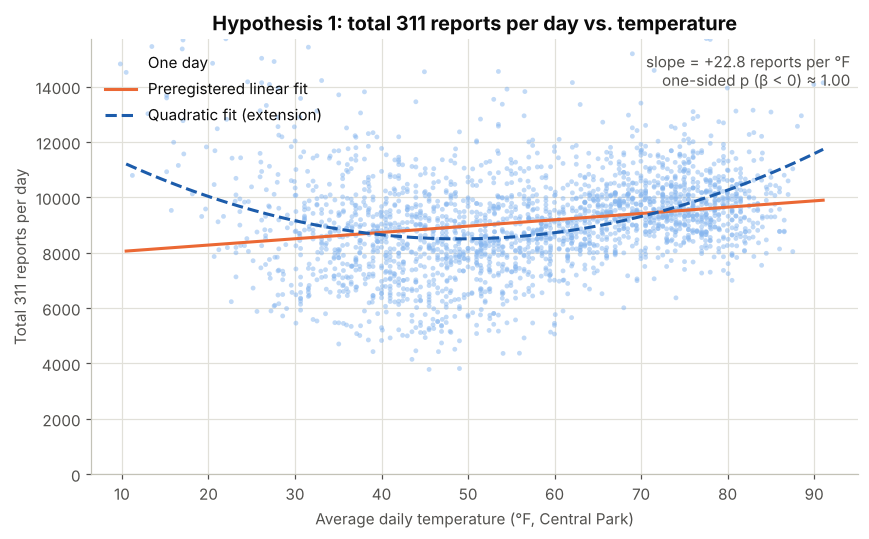

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(totals_daily["CP_TAVG"], totals_daily["REQUESTS"], s=10, color=LIGHT_BLUE, alpha=0.5,
           edgecolors="none", label="One day")

grid = pd.DataFrame({"CP_TAVG": np.linspace(totals_daily["CP_TAVG"].min(), totals_daily["CP_TAVG"].max(), 100)})
linear_fit = h1_models["Preregistered: OLS, temperature only"].predict(grid)
quadratic_fit = smf.ols("REQUESTS ~ CP_TAVG + I(CP_TAVG ** 2)", totals_daily).fit().predict(grid)
ax.plot(grid["CP_TAVG"], linear_fit, color=ORANGE, linewidth=2, label="Preregistered linear fit")
ax.plot(grid["CP_TAVG"], quadratic_fit, color=DARK_BLUE, linewidth=2, linestyle="--", label="Quadratic fit (extension)")

beta = h1_models["Preregistered: OLS, temperature only"].params["CP_TAVG"]
ax.text(0.99, 0.97, f"slope = {beta:+.1f} reports per °F\none-sided p (β < 0) ≈ 1.00",
        transform=ax.transAxes, ha="right", va="top", color=MUTED_INK)
ax.set_ylim(0, totals_daily["REQUESTS"].quantile(0.995))
ax.set_title("Hypothesis 1: total 311 reports per day vs. temperature")
ax.set_xlabel("Average daily temperature (°F, Central Park)")
ax.set_ylabel("Total 311 reports per day")
ax.legend(loc="upper left")
plt.tight_layout()
fig.savefig("figures/h1_total_vs_temperature.png", dpi=150)
plt.show()

**Result for H1: we fail to reject the null hypothesis.**

* The preregistered slope is **+22.8 reports per day for each 1°F** (95% CI 18.6 to 27.0). It points the *opposite* way from our hypothesis, so the one-sided p-value for β < 0 is ≈ 1.00.
  Warmer days have slightly *more* total 311 reports, not fewer.
* This is not a fluke of the test. The positive slope stays clearly away from 0 with HAC standard errors (95% CI 10.9 to 34.7) and with calendar controls (+24.8, 95% CI 15.8 to 33.8).
* **Controlling for snowfall does not change this** (reviewer question 2): with snowfall and the calendar in the model, the temperature slope is still +24.8 (95% CI 15.8 to 33.9),
  and snowfall itself has no detectable effect on the total (+1 report per inch, 95% CI −150 to 152, p = 0.99). Snow raises some types (SnowIce, Heat) and lowers others
  (StreetNoise, IllegalParking; section 10c), so the effects cancel out in the total.
* **Temperature alone explains very little:** R² = 0.045, so 95% of the day-to-day variation in total reports comes from other things. Adding the calendar raises R² to 0.36,
  which matches section 8: `year` and `is_weekend` matter more than the weather.
* **The relationship is U-shaped, not a straight line** (reviewer question 3). Both terms of the quadratic model are highly significant (p < 10⁻⁷), and the curve is lowest at about **47°F**.
  The coldest days *do* have the most reports (about 12,900 a day at 10–19°F, compared with about 8,200 at 40–49°F), which is the part of the story our hypothesis expected.
  But the 10–19°F band has only 20 days, while there are hundreds of warm days with about 9,500–9,900 reports, so a straight line slopes upward.

**Why our hypothesis was wrong.** We based H1 on heat complaints, and section 5 shows they *do* rise sharply in the cold (r = −0.81).
But the total is a sum of many types that pull in opposite directions: Heat is only about 7.5% of all complaints, and warm-weather types like StreetNoise, Fireworks,
and DamagedTree (and many types in "Other") rise in the summer. In mild-to-warm weather those outweigh Heat. Only in the coldest snaps does Heat (plus SnowIce) push the total up.
This is the main reason we moved to studying **individual complaint types** in sections 5–9: the total hides opposite effects.

### 10b. Hypothesis 2: thunder → more 311 reports

The first row is the preregistered test. The coefficient is the difference in average total reports between thunder days and non-thunder days,
so H2 predicts a **positive** coefficient. The later rows are extensions.

In [40]:
h2_models = {
    "Preregistered: OLS, thunder only": smf.ols("REQUESTS ~ CP_WT_THUNDER", totals_daily).fit(),
    "Same model, HAC (Newey-West) errors": smf.ols("REQUESTS ~ CP_WT_THUNDER", totals_daily).fit(**HAC),
    "Extension: + temperature, rain, weekday, holiday, year (HAC)":
        smf.ols(f"REQUESTS ~ CP_WT_THUNDER + CP_TAVG + CP_PRCP + {CALENDAR}", totals_daily).fit(**HAC),
}
h2_table = pd.DataFrame([coefficient_row(label, model, "CP_WT_THUNDER", "positive") for label, model in h2_models.items()])

# Reviewer question 4: the same controlled model with JFK's thunder flag instead of Central Park's
jfk_model = smf.ols(f"REQUESTS ~ JFK_WT_THUNDER + JFK_TAVG + JFK_PRCP + {CALENDAR}", totals_daily).fit(**HAC)
h2_table.loc[len(h2_table)] = coefficient_row("Robustness: JFK thunder, same controls (HAC)", jfk_model, "JFK_WT_THUNDER", "positive")

# Reviewer question 5: are reports higher the day AFTER thunder?
next_day_model = smf.ols(f"REQUESTS ~ CP_THUNDER_YESTERDAY + CP_WT_THUNDER + CP_TAVG + CP_PRCP + {CALENDAR}",
                         totals_daily).fit(**HAC)
h2_table.loc[len(h2_table)] = coefficient_row("Extension: thunder YESTERDAY, same controls (HAC)", next_day_model,
                                              "CP_THUNDER_YESTERDAY", "positive")

h2_table.set_index("model").round({"coefficient (reports/day)": 1, "95% CI low": 1, "95% CI high": 1,
                                   "t": 2, "one-sided p": 4, "R²": 3})

,coefficient (reports/day),95% CI low,95% CI high,t,one-sided p,R²
model,,,,,,
"Preregistered: OLS, thunder only",417.3,145.2,689.4,3.01,0.0013,0.004
"Same model, HAC (Newey-West) errors",417.3,94.9,739.6,2.54,0.0056,0.004
"Extension: + temperature, rain, weekday, holiday, year (HAC)",107.8,-190.1,405.6,0.71,0.2391,0.360
"Robustness: JFK thunder, same controls (HAC)",52.2,-272.1,376.5,0.32,0.3762,0.363
"Extension: thunder YESTERDAY, same controls (HAC)",363.7,7.2,720.2,2.00,0.0228,0.361


In [41]:
# Why does the effect shrink once we add controls? Thunder days are summer days.
thunder_days = totals_daily[totals_daily["CP_WT_THUNDER"] == 1]
other_days_t = totals_daily[totals_daily["CP_WT_THUNDER"] == 0]
print(f"Average total reports: thunder days {thunder_days['REQUESTS'].mean():,.0f}, other days {other_days_t['REQUESTS'].mean():,.0f}")
print(f"Average temperature:   thunder days {thunder_days['CP_TAVG'].mean():.0f}°F, other days {other_days_t['CP_TAVG'].mean():.0f}°F")
print(f"Share in June-August:  thunder days {thunder_days['MONTH'].isin([6, 7, 8]).mean():.0%}, "
      f"other days {other_days_t['MONTH'].isin([6, 7, 8]).mean():.0%}")
print(f"Days where Central Park and JFK agree on thunder: {(totals_daily['CP_WT_THUNDER'] == totals_daily['JFK_WT_THUNDER']).mean():.1%}")

Average total reports: thunder days 9,502, other days 9,085
Average temperature:   thunder days 72°F, other days 56°F
Share in June-August:  thunder days 64%, other days 22%
Days where Central Park and JFK agree on thunder: 95.7%


**Result for H2: we reject the null hypothesis in the preregistered test, but the effect is not robust.**

* **Preregistered test:** thunder days average **9,502** total reports vs. **9,085** on other days, a difference of **+417 reports per day** (about 4.6%; 95% CI 145 to 689).
  The one-sided p-value is **0.0013**, below α = 0.05, so we **reject H₀**. It stays significant with HAC standard errors (p = 0.006).
* **But the difference is mostly about the season, not the thunder.** Thunder days average 72°F vs. 56°F, and 64% of them are in June–August (vs. 22% of other days).
  Once we hold temperature, rain, day of week, holidays, and year fixed, the thunder effect shrinks to **+108 reports (95% CI −190 to 406, p = 0.24)**, which is not significant.
  R² for the thunder-only model is just 0.004.
* **Station check (reviewer question 4):** Central Park and JFK agree about thunder on 95.7% of days. With JFK's thunder flag and the same controls, the effect is also not significant
  (+52, p = 0.38), so the conclusion does not depend on the station.
* **Next-day check (reviewer question 5):** the day *after* a thunderstorm has about **+364 more reports** with all controls (one-sided p = 0.023, 95% CI 7 to 720).
  This fits how storm damage is reported: people find downed trees and flooded basements the next morning (`precip_yesterday_in` is also a top feature for DamagedTree and Sewer in section 8).
  Because this was not preregistered and the confidence interval nearly reaches 0, we treat it as a lead for future work, not a confirmed finding.

**Takeaway:** H2 passes the test we wrote down, but the extra reports on thunder days are explained by *when* thunderstorms happen (warm summer days, which already have more 311 activity).
We don't have evidence that thunder itself adds reports on the same day. A statistically significant result is not automatically a meaningful one when the predictor is tied up with the season.

### 10c. Extension: are the weather rate ratios in section 6a significant?

The rate ratios in section 6a are simple comparisons. They don't adjust for anything (snow days are also winter days), and they don't come with a p-value.
Here we test them properly with one **Poisson regression per complaint type**:

$$\log(\text{expected complaints}) = \beta_0 + \sum_{\text{conditions}} \beta_c \cdot \text{condition}_c + \text{day of week} + \text{holiday} + \text{month} + \text{year}$$

* Poisson regression is built for counts. **exp(β_c)** is an **adjusted rate ratio**: how many times more complaints a day with that condition has
  compared with an otherwise similar day (same day of the week, month, year, and holiday status) without it.
* All six condition columns go in the same model, so a snowy, freezing day gets credit for both.
* We use HAC standard errors again. They also correct for the fact that complaint counts vary much more than a plain Poisson model assumes.
* We run 8 types × 6 conditions = **48 tests**. Testing so many things at α = 0.05 would give about 2–3 false positives by chance alone,
  so we use a **Bonferroni correction**: a result counts as significant only if p < 0.05 / 48 ≈ 0.001.

In [42]:
# One Poisson regression per complaint type. Each weather condition column is a predictor, and the calendar
# (day of week, holiday, month, year) is held fixed. exp(coefficient) is an ADJUSTED rate ratio.
# HAC standard errors handle both overdispersion (variance > mean) and day-to-day correlation.
N_TESTS = len(TYPES) * len(WEATHER_CONDITIONS)        # 8 types x 6 conditions = 48 tests
BONFERRONI_ALPHA = ALPHA / N_TESTS

glm_rows = []
for complaint_type in TYPES:
    formula = (f"{complaint_type} ~ " + " + ".join(WEATHER_CONDITIONS)
               + " + C(day_of_week) + is_holiday + C(month) + C(year)")
    glm = smf.glm(formula, daily, family=sm.families.Poisson()).fit(**HAC)
    intervals = glm.conf_int()
    for condition in WEATHER_CONDITIONS:
        glm_rows.append({
            "complaint type": complaint_type,
            "condition": condition,
            "adjusted rate ratio": np.exp(glm.params[condition]),
            "95% CI low": np.exp(intervals.loc[condition, 0]),
            "95% CI high": np.exp(intervals.loc[condition, 1]),
            "p": glm.pvalues[condition],
        })

glm_results = pd.DataFrame(glm_rows)
glm_results["significant (Bonferroni)"] = glm_results["p"] < BONFERRONI_ALPHA
print(f"Bonferroni threshold: {ALPHA} / {N_TESTS} = {BONFERRONI_ALPHA:.5f}")
print(f"Significant after correction: {glm_results['significant (Bonferroni)'].sum()} of {N_TESTS}")

# the pairs we expected to matter most (section 3), with confidence intervals
expected_pairs = [("Heat", "is_freezing"), ("Sewer", "is_heavy_rain"), ("Sewer", "is_rain"),
                  ("DamagedTree", "is_windy"), ("DamagedTree", "is_heavy_rain"), ("SnowIce", "is_freezing"),
                  ("SnowIce", "is_snow"), ("StreetNoise", "is_hot"), ("Fireworks", "is_hot")]
expected = glm_results.set_index(["complaint type", "condition"]).loc[expected_pairs]
expected.style.format({"adjusted rate ratio": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p": "{:.1e}"})

Bonferroni threshold: 0.05 / 48 = 0.00104
Significant after correction: 23 of 48


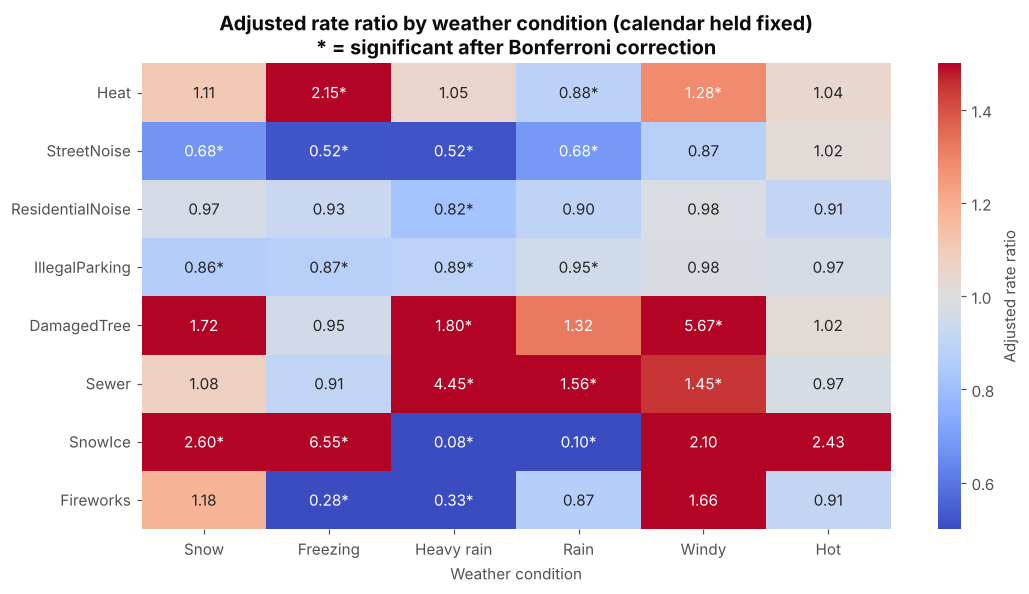

In [43]:
adjusted = glm_results.pivot(index="complaint type", columns="condition", values="adjusted rate ratio")
significant = glm_results.pivot(index="complaint type", columns="condition", values="significant (Bonferroni)")
adjusted, significant = adjusted.loc[TYPES, WEATHER_CONDITIONS], significant.loc[TYPES, WEATHER_CONDITIONS]

# cell text: the rate ratio, with * if it survives the Bonferroni correction
labels = adjusted.map(lambda value: f"{value:.2f}") + np.where(significant, "*", "")
labels.columns = condition_names
adjusted.columns = condition_names

plt.figure(figsize=(10, 5.5))
sns.heatmap(adjusted, annot=labels, fmt="", cmap="coolwarm", center=1, vmin=0.5, vmax=1.5,
            cbar_kws={"label": "Adjusted rate ratio"})
plt.title("Adjusted rate ratio by weather condition (calendar held fixed)\n* = significant after Bonferroni correction")
plt.xlabel("Weather condition")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/adjusted_rate_ratios.png", dpi=150)
plt.show()

**What the adjusted rate ratios show**

* **23 of the 48 weather effects are significant after the Bonferroni correction**, and the four storm-related pairs we expected all are:
  * **Heat on freezing days: 2.15×** (95% CI 1.93–2.40, p ≈ 10⁻⁴³). Smaller than the unadjusted 4.86× in section 6a, because part of that was just "winter".
  * **Sewer on heavy-rain days: 4.45×** (3.47–5.70) and **on rainy days: 1.56×** (1.40–1.75).
  * **DamagedTree on windy days: 5.67×** (3.01–10.72). It is *larger* than the unadjusted 4.51×, because many windy days are in the winter, when tree complaints are usually low.
  * **SnowIce on freezing days: 6.55×** (3.97–10.82) and **on snow days: 2.60×** (1.56–4.33).
* **StreetNoise falls in bad weather** (0.52× on freezing and heavy-rain days, 0.68× on snow and rain days, all significant): people stay inside.
* **The "hot day" effects disappear once the month is held fixed.** In section 6a, Fireworks was 3.7× and StreetNoise 1.4× on hot days. Adjusted, they are 0.91× and 1.02×
  and not significant. Hot days happen in June–July, which is also when the Fourth of July and outdoor season happen. The calendar, not the heat, drives these types.
* **ResidentialNoise and IllegalParking** have a few significant ratios, but they are small (0.82–0.95). With 2,402 days, even a 5% change can be "significant";
  in practical terms these types barely react to the weather.
* Some wide intervals come from rare combinations (only 59 snow days and 70 windy days). For example, DamagedTree on heavy-rain days (1.80×, 95% CI 1.27–2.54, p = 0.001)
  only just passes the Bonferroni cutoff, and DamagedTree on snow days (1.72×, p = 0.10) does not, even though both point the way we expected.

### 10d. How well does the XGBoost model hold up?

The XGBoost models (section 7) are evaluated on data they never saw: the last 365 days. That out-of-sample test is the right measure of "significance" for a prediction model,
because a model that only memorized the training data would score near or below R² = 0 on the test year.

* **Heat (R² = 0.92), StreetNoise (0.91), and Fireworks (0.65)** are predicted well on the unseen year, so their weather and calendar patterns are stable from year to year.
* **DamagedTree, Sewer, and SnowIce (R² 0.14–0.25)** are predicted poorly, even though 10c shows their weather effects are highly significant.
  These two results don't conflict: the weather clearly changes the *average* number of complaints, but a few extreme storms (for example, Oct 30, 2025 for Sewer) are far bigger than anything
  daily weather values can predict.
* **ResidentialNoise (R² = −0.18)** does worse than guessing the test-year average, so we do not draw conclusions from that model.
* Feature importance (section 8) is not a significance test. It shows what the model *used*, not what *causes* complaints, and correlated features split the credit.

## 11. Conclusions

**Research question 1: How is daily weather associated with the total number of 311 requests filed in NYC each day?**

Only weakly, and not in the way we predicted.
* Our first hypothesis (colder → more reports) was **not supported**. Total reports rise slightly with temperature (+22.8 per °F), and the real shape is a U: the most reports come
  on the coldest days (below 20°F) and on warm days, with the fewest around 47°F (section 10a).
* Our second hypothesis (thunder → more reports) passed its preregistered test (+417 reports per day, p = 0.001), but the effect **disappears once we account for temperature and the calendar**.
  Thunder days have more reports because they are summer days. The day *after* a thunderstorm may have more reports, which is worth testing in future work (section 10b).
* For the total, the calendar matters much more than the weather. Temperature alone explains about 5% of the daily variation, while adding the day of the week, holidays, and year raises that to 36%.

**Research question 2: Which complaint types rise on particular weather days?**

Here the answer is clear. Individual complaint types react strongly to the weather they are physically connected to, and these effects hold up after controlling for the calendar
and correcting for 48 tests (section 10c):
* **Heat** complaints double on freezing days (2.15×) and are almost entirely explained by temperature (R² = 0.92 on the unseen test year).
* **Sewer** complaints are 4.5× higher on heavy-rain days, **DamagedTree** complaints are 5.7× higher on windy days, and **SnowIce** complaints are 6.6× higher on freezing days and track
  the snow on the ground.
* **StreetNoise** drops by about half in freezing weather and heavy rain, and rises in warm months.
* Some patterns that look like weather are really the calendar: once the month is held fixed, hot days don't increase **Fireworks** or **StreetNoise** complaints; the Fourth of July and summer do.
  **ResidentialNoise** and **IllegalParking** depend on weekends and long-term growth, not the weather.
* The station question: for thunder, Central Park and JFK agree on 96% of days and give the same answer.

**Overall:** "Does weather affect 311?" depends on what you count. Weather effects on specific types are large and statistically significant, but they push in opposite directions
(cold raises Heat and lowers StreetNoise), so they mostly cancel out in the citywide total. The storm-driven types are where weather matters most and also where it is hardest to predict:
a few extreme events produce a large share of their complaints. For a city agency, this means daily weather forecasts are useful for planning **Heat, Sewer, tree, and snow** staffing,
but not for predicting overall 311 call volume.

## 12. Limitations

**Data gaps and how they could affect our conclusions**

1. **311 measures reports, not problems.** A complaint only exists if someone notices a problem and decides to call. Research on NYC 311 shows that reporting rates differ by neighborhood
   income, race, education, homeownership, and language, so the same problem is reported more in some places than others (Minkoff, 2016; Kontokosta & Hong, 2021).
   Our results describe *reporting behavior* across the city, and could understate weather impacts in neighborhoods that report less.
2. **One weather station for a whole city.** We use Central Park for all five boroughs. Thunderstorms and heavy rain are often local: a storm can flood Queens while Manhattan stays dry.
   This adds noise to our weather columns, which pushes estimated effects toward zero. The Sewer and DamagedTree effects might be even larger with borough-level weather.
3. **Daily resolution only.** The 311 export has no time of day, so we can't tell whether a complaint came before or after a storm on the same day.
   This is part of why next-day effects showed up (section 10b) and why we added yesterday's precipitation and snowfall as features.
4. **Missing and changing data.** DEP complaint types (including Sewer) stop on July 29, 2026 in our download, so the last month was dropped. Complaint labels were renamed over time,
   and the COVID period (2020–2021) changed how and where people lived and worked, which could shift baselines. The year controls absorb overall growth, but not every change in behavior.
5. **Few extreme days.** There are only 59 snow days, 70 windy days, and 71 holidays, and a handful of storms (Tropical Storm Isaias and the remains of Hurricane Ida; National Hurricane Center, 2021, 2022) produce a large share of
   some complaint types. Results for these conditions have wide confidence intervals and could change with a few more storms.
6. **Weather categories are our own cutoffs** (e.g. heavy rain = 1 inch or more). Different cutoffs would change the rate ratios somewhat, though not the direction of the main findings.
7. **Holidays are federal holidays only.** Days like Lunar New Year, Diwali, or Eid, which can bring fireworks and noise in some neighborhoods, are not flagged.

**Limitations of our significance metrics**

* **p-values and sample size.** With 2,402 days, very small effects can be "statistically significant" (e.g. a 5% change in IllegalParking). We report rate ratios and confidence intervals
  so the reader can judge practical size, not just significance.
* **Independence.** Regular p-values assume each day is independent. Neighboring days are correlated, so we used HAC standard errors; the regular OLS p-values in our preregistered test
  (e.g. 0.0013 for H2) are somewhat too small.
* **Multiple testing.** We ran many tests (48 in section 10c, plus several robustness checks). Bonferroni protects the 48 rate ratios, but it is conservative and may hide real but smaller effects.
  The next-day thunder result (p = 0.023) was not corrected and should be treated as exploratory.
* **Association, not causation.** None of our models can prove that weather *causes* complaints. Weather is mostly outside human control, which helps, but it is still tied to the season,
  to school schedules, and to holidays.
* **Linear model for H1.** As preregistered, H1 uses a straight line, which hides the U-shape. We report the quadratic model so the reader sees both.

**Potential harms**

* **Unequal service.** If a city used 311-based models like ours to decide where to send crews before a storm, it would send them where people *report* the most, not necessarily where the damage is.
  Neighborhoods that report less, often lower-income areas and areas with more non-English speakers, could get slower help (Kontokosta & Hong, 2021).
* **Heat complaints are a health issue.** No heat in winter can be dangerous for older people, children, and people with health conditions. Treating heat complaints as a predictable "seasonal load"
  should not lead to under-staffing the cold days with the most reports, and under-reporting tenants may be the most at risk.
* **Noise and fireworks complaints can be used against communities.** Noise complaints in NYC have been linked to neighborhood change and to more policing in communities of color (Community Service Society of New York, n.d.).
  Our fireworks and noise results describe when reports happen, not who is "causing problems", and should not be used to justify targeting particular neighborhoods.

## Questions for reviewers

1. **Adjusted vs. unadjusted rate ratios.** Section 6 shows simple rate ratios and section 10c shows Poisson rate ratios that hold the calendar fixed. They tell different stories for some pairs
   (for example, hot days and Fireworks: 3.74× unadjusted vs. 0.91× adjusted). Should the final report keep both, or replace the heatmap in 6a with the adjusted one?
2. **Bonferroni correction.** We corrected for 48 tests in section 10c. Is Bonferroni too strict here, and would a less conservative method (for example, the Benjamini–Hochberg false discovery rate) be more appropriate?
3. **Extreme storms.** A few storm days (Tropical Storm Isaias, the remains of Hurricane Ida, Oct 30, 2025) produce a large share of DamagedTree and Sewer complaints and are badly underpredicted by XGBoost.
   Should we model these days separately (for example, with a "named storm" indicator), or report the model with and without them?
4. **Next-day effects.** Thunder *yesterday* is associated with about 364 more reports today (section 10b), but this was not preregistered. Is it reasonable to present it as an exploratory finding,
   and should we test lagged weather for the individual complaint types too?
5. **Focus.** Is the XGBoost section (7–8) a useful part of the story, or would the report be more focused if we kept only the rate ratios and the significance tests?
6. **Weather station.** We use Central Park for the complaint-type analysis. Would it be worth repeating section 10c with JFK's weather, or would borough-level weather (not available in our data) be the only real improvement?

## 13. Acknowledgements and Bibliography

**Data**

* NYC Office of Technology and Innovation. (2026). *311 Service Requests from 2020 to Present* [Data set]. NYC Open Data. https://data.cityofnewyork.us/d/erm2-nwe9 (downloaded September 8, 2026).
* NOAA National Centers for Environmental Information. (2026). *Global Historical Climatology Network – Daily (GHCN-Daily)*, stations USW00094728 (Central Park) and USW00094789 (JFK) [Data set].
  Climate Data Online. https://www.ncei.noaa.gov/cdo-web/ (downloaded September 8, 2026).
* Menne, M. J., Durre, I., Vose, R. S., Gleason, B. E., & Houston, T. G. (2012). An overview of the Global Historical Climatology Network-Daily database.
  *Journal of Atmospheric and Oceanic Technology, 29*(7), 897–910. https://doi.org/10.1175/JTECH-D-11-00103.1

**Background and related work**

* NYC Department of Housing Preservation and Development. (n.d.). *Heat and hot water information*. https://www.nyc.gov/site/hpd/services-and-information/heat-and-hot-water-information.page
* Kontokosta, C. E., & Hong, B. (2021). Bias in smart city governance: How socio-spatial disparities in 311 complaint behavior impact the fairness of data-driven decisions.
  *Sustainable Cities and Society, 64*, 102503. https://doi.org/10.1016/j.scs.2020.102503
* Minkoff, S. L. (2016). NYC 311: A tract-level analysis of citizen–government contacting in New York City. *Urban Affairs Review, 52*(2), 211–246. https://doi.org/10.1177/1078087415577796
* National Hurricane Center. (2021). *Tropical Cyclone Report: Tropical Storm Isaias (AL092020)*. NOAA. https://www.nhc.noaa.gov/data/tcr/AL092020_Isaias.pdf
* National Hurricane Center. (2022). *Tropical Cyclone Report: Hurricane Ida (AL092021)*. NOAA. https://www.nhc.noaa.gov/data/tcr/AL092021_Ida.pdf
* Community Service Society of New York. (n.d.). *New neighbors and the over-policing of communities of color*. https://www.cssny.org/pages/311data
* Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92.
  https://doi.org/10.1145/3458723

**Methods and software**

* Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica, 55*(3), 703–708.
* Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.
  https://doi.org/10.1145/2939672.2939785
* Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96.
* McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
* Harris, C. R., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2
* Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
* Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.